## Dataset discovery

In [11]:


import os
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

INPUT_DIR = Path("/kaggle/input")
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".png", ".bmp", ".tif", ".tiff"}
CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]
SPLITS = ["train", "test", "val"]

print("=" * 60)
print("OCT2017 RETINAL DISEASE CLASSIFICATION")
print("=" * 60)


if not INPUT_DIR.exists():
    raise FileNotFoundError("Kaggle input directory not found.")

print("\nAttached datasets:")
for item in INPUT_DIR.iterdir():
    if item.is_dir():
        print(" -", item.name)


image_count = 0
non_image_count = 0

for root, dirs, files in os.walk(INPUT_DIR):
    dirs[:] = [d for d in dirs if d != "__MACOSX"]

    for filename in files:
        if filename == ".DS_Store" or filename.startswith("._"):
            continue

        if Path(filename).suffix.lower() in IMAGE_EXTENSIONS:
            image_count += 1
        else:
            non_image_count += 1

print(f"\nTotal images: {image_count:,}")
print(f"Total non-image files: {non_image_count:,}")


candidate_roots = []

for root, dirs, files in os.walk(INPUT_DIR):
    dirs[:] = [d for d in dirs if d != "__MACOSX"]
    current = Path(root)

    if (current / "train").is_dir() and (current / "test").is_dir():
        candidate_roots.append(current)

if not candidate_roots:
    raise FileNotFoundError(
        "Could not find a folder containing both train and test."
    )


def count_class_folders(root):
    count = 0

    for split in SPLITS:
        split_path = root / split

        if split_path.is_dir():
            count += sum(
                1 for folder in split_path.iterdir()
                if folder.is_dir() and folder.name.upper() in CLASSES
            )

    return count

candidate_roots.sort(key=count_class_folders, reverse=True)
DATA_ROOT = candidate_roots[0]

print("\nSelected dataset root:")
print(DATA_ROOT)

if len(candidate_roots) > 1:
    print(
        f"WARNING: {len(candidate_roots)} candidate roots found. "
        "Verify the selected path before training."
    )


rows = []

for split in SPLITS:
    split_path = DATA_ROOT / split

    if not split_path.is_dir():
        print(f"\nSplit not found: {split}")
        continue

    row = {"split": split}

    for class_name in CLASSES:
        class_path = next(
            (
                folder for folder in split_path.iterdir()
                if folder.is_dir() and folder.name.upper() == class_name
            ),
            None
        )

        if class_path is None:
            row[class_name] = 0
            print(f"WARNING: Missing {split}/{class_name}")
            continue

        row[class_name] = sum(
            1 for file in class_path.iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
            and not file.name.startswith("._")
        )

    row["TOTAL"] = sum(row[c] for c in CLASSES)
    rows.append(row)

if rows:
    summary = pd.DataFrame(rows).set_index("split")
    total_row = pd.DataFrame(
        [summary[CLASSES + ["TOTAL"]].sum()],
        index=["ALL"]
    )
    summary = pd.concat([summary, total_row])

    print("\nIMAGE COUNTS PER SPLIT AND CLASS:")
    display(summary)


print("\nSAMPLE IMAGE PATHS:")

shown = 0

for class_name in CLASSES:
    class_path = DATA_ROOT / "train" / class_name

    if not class_path.is_dir():
        continue

    for file in sorted(class_path.iterdir()):
        if (
            file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
            and not file.name.startswith("._")
        ):
            print(file)
            shown += 1

            if shown >= 8:
                break

    if shown >= 8:
        break

print("\nDataset inspection completed. No dataset files were modified.")


OCT2017 RETINAL DISEASE CLASSIFICATION

Attached datasets:
 - datasets

Total images: 168,968
Total non-image files: 0

Selected dataset root:
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 

IMAGE COUNTS PER SPLIT AND CLASS:


,CNV,DME,DRUSEN,NORMAL,TOTAL
train,37205,11348,8616,26315,83484
test,242,242,242,242,968
val,8,8,8,8,32
ALL,37455,11598,8866,26565,84484



SAMPLE IMAGE PATHS:
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-1.jpeg
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-10.jpeg
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-100.jpeg
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-101.jpeg
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-102.jpeg
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-103.jpeg
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-104.jpeg
/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 /train/CNV/CNV-1016042-105.jpeg

Dataset inspection completed. No dataset files were modified.


In [12]:
import os, sys, re, json, math, hashlib, warnings, random, time, itertools, shutil, platform
from pathlib import Path
from collections import Counter, defaultdict
import os
import sys
import re
import json
import math
import hashlib
import warnings
import random
import time
import itertools
import shutil
import platform

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from PIL import Image
import cv2
from tqdm.auto import tqdm
import plotly.express as px
import warnings
import plotly.graph_objects as go
from IPython.display import display, Markdown
try:
    import umap
except Exception as _e:                      # optional dependency
    umap = None
    print("umap-learn not available → UMAP panels will be skipped (pip install umap-learn needs Internet).")

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 170)
sns.set_theme(style="whitegrid", context="notebook")

# configuration
SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

ON_KAGGLE = Path("/kaggle/input").exists()
DATA_ROOT = Path(os.environ.get("OCT_DATA_ROOT", "/kaggle/input"))          # searched recursively
WORK = Path(os.environ.get("OCT_WORK_DIR", "/kaggle/working" if ON_KAGGLE else "./task1_work"))
WORK.mkdir(parents=True, exist_ok=True); os.chdir(WORK); sys.path.insert(0, str(WORK))
OUT = WORK / "task1_outputs"; FIG_DIR = OUT / "figures"; TAB_DIR = OUT / "tables"; INT_DIR = OUT / "interactive"
for d in (FIG_DIR, TAB_DIR, INT_DIR): d.mkdir(parents=True, exist_ok=True)

_m = os.environ.get("OCT_MAX_PER_SPLIT_CLASS", "")
MAX_PER_SPLIT_CLASS = int(_m) if _m.strip() else None     # None = analyse every image
USE_CACHE = True

# reproducibility switches
ANALYSE_TREE_HINT = "oct2017/OCT2017"   
SCAN_ALL_TREES = True                    

CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]
CLASS_COLORS = {"CNV": "#d95f02", "DME": "#1b9e77", "DRUSEN": "#7570b3", "NORMAL": "#666666"}
SPLIT_ALIASES = {"train": "train", "training": "train", "test": "test", "testing": "test",
                 "val": "val", "valid": "val", "validation": "val"}
IMG_EXT = {".jpeg", ".jpg", ".png", ".tif", ".tiff", ".bmp"}

# Data-quality thresholds 
BLANK_STD_MAX = 2.0          # grey-level std below this => near-blank
LOW_CONTRAST_STD_MAX = 10.0  # RMS contrast below this => very low contrast
PHASH_MAX_DIST = 2           # Hamming distance (of 64 bits) for near-duplicate CANDIDATES
PHASH_BUCKET_CAP = 1500      # hash buckets larger than this are skipped (reported → count is a lower bound)
VERIFY_SIZE = 256            # hash candidates are verified by comparing pixels at this size …
VERIFY_MAD_MAX = 3.0         # … a pair counts as a VERIFIED near-duplicate if mean |difference| ≤ this many grey levels (true copies, even re-encoded or flipped, are typically ~0–3; check the MAD histogram and adjust)
VERIFY_MAX_PAIRS = 20000     # verify at most this many candidate pairs (closest hashes first)

# Dimensionality-reduction settings
TSNE_N = 4000; UMAP_N = 8000; THUMB = 32
TSNE_PARAMS = dict(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
UMAP_PARAMS = dict(n_components=2, n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=SEED)
USE_EFFNET_EMBEDDINGS = False   # optional frozen ImageNet features; needs torchvision weights (Internet or an uploaded weights dataset)

R = {}   # key results → eda_summary.json

def say(title, bullets):
    """Print auto-generated, rule-based implications for later model design (numbers come from this run)."""
    display(Markdown(f"** Implications for later model design — {title}** *(auto-generated from the numbers above; verify before quoting)*\n\n"
                     + "\n".join(f"- {b}" for b in bullets)))

print("Kaggle:", ON_KAGGLE, "| DATA_ROOT:", DATA_ROOT, "| exists:", DATA_ROOT.exists())
print("Outputs →", OUT)

Kaggle: True | DATA_ROOT: /kaggle/input | exists: True
Outputs → /kaggle/working/task1_outputs


In [13]:
import sklearn, scipy
vers = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
        "scipy": scipy.__version__, "matplotlib": matplotlib.__version__, "seaborn": sns.__version__, "plotly": __import__("plotly").__version__,
        "opencv": cv2.__version__, "pillow": Image.__version__, "umap-learn": getattr(umap, "__version__", "missing")}
try:
    import torch; vers["torch"] = torch.__version__; vers["cuda_available"] = bool(torch.cuda.is_available())
except Exception:
    vers["torch"] = "not imported (not needed for Task 1)"
print("CPU cores:", os.cpu_count()); print(json.dumps(vers, indent=2))
R["environment"] = vers

def show_tree(root, max_depth=3, max_lines=60):
    root = Path(root); lines = 0
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if depth > max_depth: dirnames[:] = []; continue
        dirnames.sort(); print(f"{'  '*depth}{Path(dirpath).name or str(root)}/  ({len(filenames)} files here)"); lines += 1
        if lines >= max_lines: print("  … (truncated)"); break
show_tree(DATA_ROOT)

CPU cores: 4
{
  "python": "3.13.15",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scikit-learn": "1.6.1",
  "scipy": "1.16.3",
  "matplotlib": "3.10.0",
  "seaborn": "0.13.2",
  "plotly": "5.24.1",
  "opencv": "4.14.0",
  "pillow": "12.3.0",
  "umap-learn": "0.5.12",
  "torch": "2.11.0+cu128",
  "cuda_available": true
}
input/  (0 files here)
  datasets/  (0 files here)
    paultimothymooney/  (0 files here)
      kermany2018/  (0 files here)


In [14]:
def discover_files(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Walk the dataset root. Returns (image_inventory, non_image_files)."""
    rows, other = [], []
    for p in root.rglob("*"):
        if p.is_dir():
            continue
        if p.name.startswith("."):          # hidden files report
            other.append({"path": str(p), "name": p.name, "size_bytes": p.stat().st_size}); continue
        if p.suffix.lower() not in IMG_EXT:
            other.append({"path": str(p), "name": p.name, "size_bytes": p.stat().st_size})
            continue
        label = p.parent.name.strip().upper()
        split_raw = p.parent.parent.name.strip().lower()
        split = SPLIT_ALIASES.get(split_raw, "unknown")
        try:
            tree = str(p.parent.parent.parent.relative_to(root)) or "."
        except ValueError:
            tree = "."
        m = re.match(r"^(?P<cls>[A-Za-z]+)-(?P<pid>\d+)-(?P<num>\d+)$", p.stem)
        rows.append({
            "path": str(p), "tree": tree, "split": split, "label": label, "filename": p.name,
            "ext": p.suffix.lower(), "size_bytes": p.stat().st_size,
            "file_cls": m.group("cls").upper() if m else None,
            "file_pid": m.group("pid") if m else None,
            "file_num": int(m.group("num")) if m else None,
        })
    return pd.DataFrame(rows), pd.DataFrame(other)

assert DATA_ROOT.exists(), f"DATA_ROOT {DATA_ROOT} not found — download the dataset and set DATA_ROOT (see Section 0)."
SCAN_ROOT = DATA_ROOT
if not SCAN_ALL_TREES:
    SCAN_ROOT = next((r for r in candidate_roots if ANALYSE_TREE_HINT in str(r)), DATA_ROOT)
    print("SCAN_ALL_TREES=False -> scanning only:", SCAN_ROOT)
t0 = time.time()
inv_all, non_img = discover_files(SCAN_ROOT)
print(f"Scanned {len(inv_all):,} image files and {len(non_img):,} non-image files in {time.time()-t0:.1f}s")
assert len(inv_all) > 0, "No image files found under DATA_ROOT."

# Multiple dataset trees
tree_counts = inv_all["tree"].value_counts()
print("\nDataset trees found (relative to DATA_ROOT):")
print(tree_counts.to_string())
ANALYSE_TREE = next((t for t in tree_counts.index if ANALYSE_TREE_HINT in t), tree_counts.index[0])   # pinned by hint; otherwise the largest tree
R["analysed_tree"] = str(ANALYSE_TREE)
if len(tree_counts) > 1:
    print(f"\n⚠ More than one tree detected. Analysing only {ANALYSE_TREE!r}. "
          "Check whether the others are duplicate copies before combining anything.")
inv = inv_all[inv_all["tree"] == ANALYSE_TREE].copy()
unk = inv[(inv["split"] == "unknown") | (~inv["label"].isin(CLASSES))]
print(f"\nFiles with unrecognised split or class folder in analysed tree: {len(unk)}")
if len(unk):
    display(unk.head())
inv = inv[(inv["split"] != "unknown") & (inv["label"].isin(CLASSES))].reset_index(drop=True)

inv_full = inv.copy()                          # counts before any dry-run subsampling
if MAX_PER_SPLIT_CLASS:                       # optional dry-run subsample (seeded)
    inv = (inv.groupby(["split", "label"], group_keys=False)
              .apply(lambda g: g.sample(min(len(g), MAX_PER_SPLIT_CLASS), random_state=SEED))
              .reset_index(drop=True))
    print(f"⚠ DRY RUN: subsampled to at most {MAX_PER_SPLIT_CLASS} images per split×class.")

print("\nNon-image files found (possible metadata / documentation):")
display(non_img.head(20) if len(non_img) else Markdown("*none*"))

inventory = (inv.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0))
inventory["TOTAL"] = inventory.sum(axis=1)
inventory.loc["ALL"] = inventory.sum()
print("\nACTUAL — images per split × class (from folder structure):")
display(inventory)
print("\nFile extensions:", dict(Counter(inv["ext"])))
print("Filenames matching '<disease>-<id>-<number>':",
      f"{inv['file_pid'].notna().mean()*100:.2f}%")
mism = inv[inv["file_cls"].notna() & (inv["file_cls"] != inv["label"])]
print("Filename disease prefix ≠ folder label:", len(mism))
inventory.to_csv(TAB_DIR / "inventory_split_by_class.csv")
R["inventory"] = inventory.to_dict()
R["n_trees"] = int(len(tree_counts))


Scanned 168,968 image files and 84,521 non-image files in 568.1s

Dataset trees found (relative to DATA_ROOT):
tree
datasets/paultimothymooney/kermany2018/oct2017/OCT2017     84484
datasets/paultimothymooney/kermany2018/OCT2017             84484

⚠ More than one tree detected. Analysing only 'datasets/paultimothymooney/kermany2018/oct2017/OCT2017 '. Check whether the others are duplicate copies before combining anything.

Files with unrecognised split or class folder in analysed tree: 0

Non-image files found (possible metadata / documentation):


,path,name,size_bytes
0,/kaggle/input/datasets/paultimothymooney/kerma...,.DS_Store,10244
1,/kaggle/input/datasets/paultimothymooney/kerma...,._OCT2017,212
2,/kaggle/input/datasets/paultimothymooney/kerma...,._.DS_Store,120
3,/kaggle/input/datasets/paultimothymooney/kerma...,._train,212
4,/kaggle/input/datasets/paultimothymooney/kerma...,._test,212
5,/kaggle/input/datasets/paultimothymooney/kerma...,._DRUSEN,212
6,/kaggle/input/datasets/paultimothymooney/kerma...,._NORMAL,212
7,/kaggle/input/datasets/paultimothymooney/kerma...,._.DS_Store,120
8,/kaggle/input/datasets/paultimothymooney/kerma...,._DME,212
9,/kaggle/input/datasets/paultimothymooney/kerma...,._CNV,212



ACTUAL — images per split × class (from folder structure):


label,CNV,DME,DRUSEN,NORMAL,TOTAL
split,,,,,
test,242,242,242,242,968
train,37205,11348,8616,26315,83484
val,8,8,8,8,32
ALL,37455,11598,8866,26565,84484



File extensions: {'.jpeg': 84484}
Filenames matching '<disease>-<id>-<number>': 100.00%
Filename disease prefix ≠ folder label: 0


In [15]:
REFERENCE_LAYOUTS = {
    "v2 as reported by Tampu et al. (the Kaggle-style layout)": {"train": 83484, "val": 32, "test": 968},
    "v3 as reported by Tampu et al. (latest Mendeley release)": {"train": 108312, "test": 1000},
}
found = {s: int(n) for s, n in inv_full.groupby("split").size().items()}
print("ACTUAL — images found per split in the analysed tree:", found, "| total:", sum(found.values()))
print("DOCUMENTED — Kaggle page advertises 84,495 images; difference to what we found:", 84495 - sum(found.values()))
for name, ref in REFERENCE_LAYOUTS.items():
    same = all(found.get(k) == v for k, v in ref.items()) and set(found) == set(ref)
    print(f"  matches {name}: {same}   (reference {ref})")
R["found_split_sizes"] = found
R["layout_matches_v2"] = bool(all(found.get(k) == v for k, v in REFERENCE_LAYOUTS[list(REFERENCE_LAYOUTS)[0]].items()) and set(found) == {"train", "val", "test"})
R["layout_matches_v3"] = bool(all(found.get(k) == v for k, v in REFERENCE_LAYOUTS[list(REFERENCE_LAYOUTS)[1]].items()) and set(found) == {"train", "test"})
print("\nTotal files in analysed tree by extension:", dict(Counter(inv_full["ext"])))
print("Non-image / hidden-looking files in DATA_ROOT (count):", len(non_img))

ACTUAL — images found per split in the analysed tree: {'test': 968, 'train': 83484, 'val': 32} | total: 84484
DOCUMENTED — Kaggle page advertises 84,495 images; difference to what we found: 11
  matches v2 as reported by Tampu et al. (the Kaggle-style layout): True   (reference {'train': 83484, 'val': 32, 'test': 968})
  matches v3 as reported by Tampu et al. (latest Mendeley release): False   (reference {'train': 108312, 'test': 1000})

Total files in analysed tree by extension: {'.jpeg': 84484}
Non-image / hidden-looking files in DATA_ROOT (count): 84521


In [16]:
from pathlib import Path

utility_code = r'''
import hashlib
import numpy as np
from PIL import Image, ImageFile
import cv2


def _phash_hex(gray_u8):
    """Return a 64-bit perceptual hash as 16 hexadecimal characters."""
    small = cv2.resize(
        gray_u8, (32, 32), interpolation=cv2.INTER_AREA
    ).astype(np.float32)

    block = cv2.dct(small)[:8, :8]
    bits = block > np.median(block)

    value = 0
    for bit in bits.ravel():
        value = (value << 1) | int(bit)

    return format(value, "016x")


def analyse_image(path):
    """
    Extract file metadata, image quality statistics, intensity histogram,
    and duplicate-detection hashes.

    Returns a dictionary and does not raise exceptions for individual images.
    """
    path = str(path)

    out = {
        "path": path,
        "readable": False,
        "error": ""
    }

    try:
        # Read original file bytes for exact duplicate detection.
        with open(path, "rb") as f:
            raw = f.read()

        out["file_size_bytes"] = len(raw)
        out["sha256"] = hashlib.sha256(raw).hexdigest()

        # Fully decode the image to detect corrupted files.
        with Image.open(path) as im:
            im.load()

            out.update({
                "format": im.format,
                "mode": im.mode,
                "width": im.width,
                "height": im.height,
                "aspect_ratio": float(im.width / im.height)
            })

            rgb = np.asarray(im.convert("RGB"))
            out["channels_identical"] = bool(
                np.array_equal(rgb[..., 0], rgb[..., 1])
                and np.array_equal(rgb[..., 0], rgb[..., 2])
            )

            gray = np.asarray(im.convert("L"), dtype=np.uint8)

        # Basic image validation.
        if gray.size == 0:
            raise ValueError("Image contains no pixels")

        if gray.ndim != 2:
            raise ValueError("Grayscale conversion did not produce a 2D image")

        # Exact perceptual hashes, including horizontal flip comparison.
        out["phash"] = _phash_hex(gray)
        out["phash_flip"] = _phash_hex(
            np.ascontiguousarray(gray[:, ::-1])
        )

        # Pixel intensity statistics.
        hist = np.bincount(gray.ravel(), minlength=256)
        levels = np.arange(256, dtype=np.float64)
        n = gray.size

        probabilities = hist[hist > 0] / n
        mean = float(np.sum(hist * levels) / n)
        variance = float(np.sum(hist * (levels - mean) ** 2) / n)

        cdf = np.cumsum(hist)

        def percentile_intensity(p):
            return int(np.searchsorted(cdf, p * n, side="left"))

        occupied = np.flatnonzero(hist)
        min_int = int(occupied[0])
        max_int = int(occupied[-1])

        # Contrast and image information statistics.
        entropy = float(
            -np.sum(probabilities * np.log2(probabilities))
        )

        # Edge density and Laplacian variance are useful quality indicators,
        # but should not be treated as definitive quality scores.
        edges = cv2.Canny(gray, 50, 150)
        laplacian = cv2.Laplacian(gray, cv2.CV_64F)

        out.update({
            "mean_int": mean,
            "median_int": percentile_intensity(0.50),
            "std_int": variance ** 0.5,
            "min_int": min_int,
            "max_int": max_int,
            "q25_int": percentile_intensity(0.25),
            "q75_int": percentile_intensity(0.75),
            "michelson": float(
                (max_int - min_int) / (max_int + min_int + 1e-9)
            ),
            "entropy": entropy,
            "edge_density": float(np.mean(edges > 0)),
            "lap_var": float(laplacian.var()),
            "frac_zero": float(hist[0] / n),
            "frac_255": float(hist[255] / n),
            "hist": hist.tolist(),
            "readable": True
        })

    except Exception as e:
        out["error"] = f"{type(e).__name__}: {e}"[:200]

    return out


def hamming_distance(hash_a, hash_b):
    """Count differing bits between two 64-bit hexadecimal hashes."""
    return (int(hash_a, 16) ^ int(hash_b, 16)).bit_count()
'''

Path("oct_utils.py").write_text(utility_code, encoding="utf-8")
print("Saved oct_utils.py successfully.")


Saved oct_utils.py successfully.


In [17]:

import importlib
import oct_utils

importlib.reload(oct_utils)

print("Utility imported:", callable(oct_utils.analyse_image))

sample_path = inv_full.iloc[0]["path"]
result = oct_utils.analyse_image(sample_path)

print("Readable:", result["readable"])
print("Image size:", result.get("width"), "×", result.get("height"))
print("Format:", result.get("format"))
print("Mean intensity:", result.get("mean_int"))
print("Entropy:", result.get("entropy"))
print("SHA-256:", result.get("sha256", "")[:16], "...")
print("Error:", result["error"])


Utility imported: True
Readable: True
Image size: 512 × 496
Format: JPEG
Mean intensity: 48.855693201864916
Entropy: 6.894405969863623
SHA-256: 8ec67b1f0141737a ...
Error: 


In [18]:

import os
import time
import importlib
import numpy as np
import pandas as pd

from collections import defaultdict
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm

import oct_utils
importlib.reload(oct_utils)

# Configuration
META_CSV = TAB_DIR / "image_metadata.csv.gz"
HIST_NPZ = TAB_DIR / "hist_sums.npz"
USE_CACHE = True


source_inv = inv.copy()

source_inv["path"] = source_inv["path"].astype(str)

def extract_all(paths, n_workers):
    results = []

    if n_workers <= 1 or len(paths) < 300:
        for path in tqdm(paths, desc="Analyzing OCT images"):
            results.append(oct_utils.analyse_image(path))
    else:
        with ProcessPoolExecutor(max_workers=n_workers) as executor:
            iterator = executor.map(
                oct_utils.analyse_image,
                paths,
                chunksize=16
            )

            for result in tqdm(
                iterator,
                total=len(paths),
                desc="Analyzing OCT images"
            ):
                results.append(result)

    return results



cache_ok = (
    USE_CACHE
    and META_CSV.exists()
    and HIST_NPZ.exists()
)

if cache_ok:
    meta = pd.read_csv(META_CSV, dtype={"file_pid": str, "phash": str, "phash_flip": str, "sha256": str})   # v2: keep IDs/hashes as text

    if (
        "path" not in meta.columns
        or set(meta["path"].astype(str)) != set(source_inv["path"])
    ):
        print("Cache does not match the current inventory; recomputing.")
        cache_ok = False

if cache_ok:
    z = np.load(HIST_NPZ)
    HIST = {
        tuple(key.split("|", 1)): z[key]
        for key in z.files
    }
    z.close()

    print(
        f"Loaded cached metadata for {len(meta):,} images "
        f"from {META_CSV.name}"
    )

else:
    # Start with a conservative worker count for Kaggle.
    n_workers = min(4, max(1, (os.cpu_count() or 2) - 1))

    start_time = time.time()

    results = extract_all(
        source_inv["path"].tolist(),
        n_workers
    )

    elapsed = time.time() - start_time

    print(
        f"Analyzed {len(results):,} images in {elapsed:.0f} seconds "
        f"using {n_workers} worker(s)"
    )

    # Exclude per-pixel histograms from the metadata table.
    stats_df = pd.DataFrame([
        {key: value for key, value in result.items() if key != "hist"}
        for result in results
    ])

    # Ensure metadata aligns with the inventory.
    meta = source_inv.merge(
        stats_df,
        on="path",
        how="left",
        validate="one_to_one"
    )

    # Match the actual size column provided by oct_utils.py.
    if "file_size_bytes" in meta.columns:
        meta["size_bytes"] = meta["file_size_bytes"]

    # Sum intensity histograms by split and class.
    HIST = defaultdict(lambda: np.zeros(256, dtype=np.int64))

    lookup = meta.set_index("path")[["split", "label"]].to_dict("index")

    for result in tqdm(results, desc="Summing histograms"):
        if result["readable"]:
            key = (
                lookup[result["path"]]["split"],
                lookup[result["path"]]["label"]
            )
            HIST[key] += np.asarray(result["hist"], dtype=np.int64)

    HIST = dict(HIST)

    # Save
    meta.to_csv(META_CSV, index=False, compression="gzip")

    np.savez_compressed(
        HIST_NPZ,
        **{
            f"{split}|{label}": histogram
            for (split, label), histogram in HIST.items()
        }
    )

    print("Saved metadata and histogram cache.")

# Normalize metadata
meta["readable"] = (
    meta["readable"]
    .fillna(False)
    .astype(bool)
)

if "width" in meta.columns and "height" in meta.columns:
    meta["aspect_ratio"] = meta["width"] / meta["height"]
    meta["pixels"] = meta["width"] * meta["height"]

if "size_bytes" in meta.columns:
    meta["file_kb"] = meta["size_bytes"] / 1024

print(
    f"Readable images: {int(meta['readable'].sum()):,} / {len(meta):,}"
    f" | Unreadable: {int((~meta['readable']).sum()):,}"
)

display(meta.head(3).T.head(30))


Analyzing OCT images:   0%|          | 0/84484 [00:00<?, ?it/s]

Analyzed 84,484 images in 760 seconds using 3 worker(s)


Summing histograms:   0%|          | 0/84484 [00:00<?, ?it/s]

Saved metadata and histogram cache.
Readable images: 84,484 / 84,484 | Unreadable: 0


,0,1,2
path,/kaggle/input/datasets/paultimothymooney/kerma...,/kaggle/input/datasets/paultimothymooney/kerma...,/kaggle/input/datasets/paultimothymooney/kerma...
tree,datasets/paultimothymooney/kermany2018/oct2017...,datasets/paultimothymooney/kermany2018/oct2017...,datasets/paultimothymooney/kermany2018/oct2017...
split,train,train,train
label,DRUSEN,DRUSEN,DRUSEN
filename,DRUSEN-8549730-37.jpeg,DRUSEN-7763772-36.jpeg,DRUSEN-8082730-4.jpeg
ext,.jpeg,.jpeg,.jpeg
size_bytes,40689,53103,36535
file_cls,DRUSEN,DRUSEN,DRUSEN
file_pid,8549730,7763772,8082730
file_num,37,36,4


In [19]:

# DATASET SUMMARY — OCT IMAGE EDA


import numpy as np
import pandas as pd
from pathlib import Path


ok = meta.loc[meta["readable"].fillna(False).astype(bool)].copy()
n_total = len(meta)

expected_splits = ["train", "val", "test"]

split_sizes = (
    meta["split"]
    .value_counts()
    .reindex(expected_splits, fill_value=0)
    .astype(int)
)

cls_counts = (
    meta["label"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .astype(int)
)

# Calculate imbalance ratio only when all expected classes exist.
nonzero_counts = cls_counts[cls_counts > 0]

if len(nonzero_counts) == len(CLASSES):
    imb_ratio = float(nonzero_counts.max() / nonzero_counts.min())
else:
    imb_ratio = np.nan



if {"width", "height"}.issubset(ok.columns) and not ok.empty:
    size_counts = (
        ok.groupby(["width", "height"], dropna=False)
        .size()
        .sort_values(ascending=False)
    )
else:
    size_counts = pd.Series(dtype="int64")

if len(size_counts) > 0:
    modal_size = size_counts.index[0]
    modal_pct = float(size_counts.iloc[0] / len(ok) * 100)

    dimension_text = (
        f"{len(size_counts)} distinct (width × height) sizes; "
        f"most common {int(modal_size[0])} × {int(modal_size[1])} "
        f"({modal_pct:.1f}% of readable images)"
    )

    modal_size_output = [int(modal_size[0]), int(modal_size[1])]
else:
    modal_size = (np.nan, np.nan)
    dimension_text = "No readable images available"
    modal_size_output = [None, None]

if "mode" in ok.columns:
    modes_text = str(ok["mode"].value_counts().to_dict())
else:
    modes_text = "Not available"

if {"mode", "channels_identical"}.issubset(ok.columns):
    identical_non_gray = int(
        (
            (ok["mode"] != "L")
            & ok["channels_identical"].fillna(False).astype(bool)
        ).sum()
    )
else:
    identical_non_gray = 0

dimension_text += (
    f"; image modes: {modes_text}; "
    f"non-L-mode files with identical RGB channels: {identical_non_gray:,}"
)



if "ext" in meta.columns:
    extension_text = ", ".join(
        f"{key}: {value:,}"
        for key, value in meta["ext"].value_counts(dropna=False).items()
    )
else:
    extension_text = "Not available"

if "format" in ok.columns:
    decoder_text = ", ".join(
        f"{key}: {value:,}"
        for key, value in ok["format"].value_counts(dropna=False).items()
    )
else:
    decoder_text = "Not available"

formats_text = (
    f"File extensions: {extension_text} | "
    f"Decoded formats: {decoder_text}"
)


if {"width", "height"}.issubset(ok.columns) and not ok.empty:
    pixel_counts = ok["width"] * ok["height"]
    median_pixels = int(pixel_counts.median())
else:
    median_pixels = None

if median_pixels is not None:
    raw_pixel_text = (
        f"Approximately {median_pixels:,} pixels per image "
        "(median); no tabular features are supplied as the original input"
    )
else:
    raw_pixel_text = "Pixel count unavailable because no readable images exist"


ENG_FEATURES = [
    "mean_int",
    "median_int",
    "std_int",
    "min_int",
    "max_int",
    "q25_int",
    "q75_int",
    "michelson",
    "entropy",
    "edge_density",
    "lap_var",
    "frac_zero",
    "frac_255",
    "width",
    "height",
    "aspect_ratio",
    "file_kb",
]

available_features = [col for col in ENG_FEATURES if col in meta.columns]
missing_features = [col for col in ENG_FEATURES if col not in meta.columns]

engineered_text = (
    f"{len(available_features)} available out of {len(ENG_FEATURES)} listed: "
    + ", ".join(available_features)
)

if missing_features:
    engineered_text += " | Not available: " + ", ".join(missing_features)



if "file_pid" in meta.columns and n_total > 0:
    id_present = float(meta["file_pid"].notna().mean() * 100)
else:
    id_present = 0.0


if "non_img" in globals():
    non_image_count = len(non_img)
else:
    non_image_count = None

if non_image_count is not None:
    non_image_text = (
        f"{non_image_count:,} non-image files counted by the earlier inventory"
    )
else:
    non_image_text = "Non-image file count was not available"

patient_text = (
    f"Filename-embedded ID parsed for {id_present:.2f}% of files. "
    "This is a filename-derived identifier, not independently verified "
    "patient-level ground truth. Age, sex, eye side, device, scan-volume, "
    "and visit information cannot be confirmed from the metadata shown. "
    + non_image_text
    + "."
)



if n_total > 0:
    class_distribution_text = "; ".join(
        f"{class_name}: {count:,} ({count / n_total * 100:.1f}%)"
        for class_name, count in cls_counts.items()
    )
else:
    class_distribution_text = "No images found"

if np.isfinite(imb_ratio):
    class_distribution_text += f" | max/min imbalance ratio = {imb_ratio:.2f}"
else:
    class_distribution_text += (
        " | imbalance ratio unavailable because at least one expected class "
        "has zero images"
    )

n_unreadable = int((~meta["readable"].fillna(False).astype(bool)).sum())



summary_rows = [
    (
        "Dataset name",
        "Retinal OCT Images (optical coherence tomography), Kermany et al. 2018",
        "documented (Kaggle / Mendeley)",
    ),
    (
        "Source and URL",
        "https://www.kaggle.com/datasets/paultimothymooney/kermany2018 ; "
        "original: Mendeley Data DOI 10.17632/rscbjbr9sj.3 ; "
        "paper DOI: 10.1016/j.cell.2018.02.010",
        "documented",
    ),
    (
        "Application area",
        "Computer-aided retinal disease classification from OCT B-scans "
        "(CNV, DME, DRUSEN, NORMAL)",
        "documented",
    ),
    (
        "Total number of samples (images)",
        f"{n_total:,} found in the current inventory; "
        "Kaggle page advertises 84,495",
        "computed vs documented",
    ),
    (
        "Number of diagnostic classes",
        f"{meta['label'].nunique() if 'label' in meta.columns else 0}",
        "computed",
    ),
    (
        "Class names",
        ", ".join(sorted(meta["label"].dropna().astype(str).unique()))
        if "label" in meta.columns else "Not available",
        "computed",
    ),
    (
        "Image formats",
        formats_text,
        "computed",
    ),
    (
        "Image dimensions / channels",
        dimension_text,
        "computed",
    ),
    (
        "Features — raw pixels",
        raw_pixel_text,
        "computed",
    ),
    (
        "Features — engineered image-level",
        engineered_text,
        "computed in this notebook",
    ),
    (
        "Features — CNN embeddings",
        "None are assumed to be stored in the original dataset. "
        "EfficientNet-B0 embeddings are optional derived features and should "
        "only be reported if that extraction section is actually run.",
        "not part of original dataset",
    ),
    (
        "Patient / subject information",
        patient_text,
        "computed + documentation limitation",
    ),
    (
        "Existing train / val / test sizes",
        " | ".join(
            f"{split}: {split_sizes[split]:,}"
            for split in expected_splits
        ),
        "computed",
    ),
    (
        "Class distribution / imbalance ratio",
        class_distribution_text,
        "computed",
    ),
    (
        "Missing or corrupted images",
        f"{n_unreadable:,} unreadable out of {n_total:,} images",
        "computed using full image decoding",
    ),
    (
        "Duplicates / near-duplicates",
        "Pending exact-hash and perceptual-hash analysis in Section C",
        "pending analysis",
    ),
]

summary_df = pd.DataFrame(
    summary_rows,
    columns=["Field", "Value", "Basis"]
)



Path(TAB_DIR).mkdir(parents=True, exist_ok=True)

summary_path = Path(TAB_DIR) / "A_dataset_summary.csv"
summary_df.to_csv(summary_path, index=False)



if "R" not in globals() or not isinstance(R, dict):
    R = {}

R.update({
    "n_images": int(n_total),
    "split_sizes": split_sizes.to_dict(),
    "class_counts": cls_counts.to_dict(),
    "imbalance_ratio": float(imb_ratio) if np.isfinite(imb_ratio) else None,
    "n_unreadable": n_unreadable,
    "n_distinct_sizes": int(len(size_counts)),
    "modal_size": modal_size_output,
})



print("Dataset summary completed.")
print(f"Total images: {n_total:,}")
print(f"Readable images: {len(ok):,}")
print(f"Unreadable images: {n_unreadable:,}")
print(f"Summary saved to: {summary_path}")

with pd.option_context("display.max_colwidth", 220):
    display(summary_df)


Dataset summary completed.
Total images: 84,484
Readable images: 84,484
Unreadable images: 0
Summary saved to: /kaggle/working/task1_outputs/tables/A_dataset_summary.csv


,Field,Value,Basis
0,Dataset name,"Retinal OCT Images (optical coherence tomography), Kermany et al. 2018",documented (Kaggle / Mendeley)
1,Source and URL,https://www.kaggle.com/datasets/paultimothymooney/kermany2018 ; original: Mendeley Data DOI 10.17632/rscbjbr9sj.3 ; paper DOI: 10.1016/j.cell.2018.02.010,documented
2,Application area,"Computer-aided retinal disease classification from OCT B-scans (CNV, DME, DRUSEN, NORMAL)",documented
3,Total number of samples (images),"84,484 found in the current inventory; Kaggle page advertises 84,495",computed vs documented
4,Number of diagnostic classes,4,computed
5,Class names,"CNV, DME, DRUSEN, NORMAL",computed
6,Image formats,"File extensions: .jpeg: 84,484 | Decoded formats: JPEG: 84,484",computed
7,Image dimensions / channels,6 distinct (width × height) sizes; most common 512 × 496 (45.8% of readable images); image modes: {'L': 84484}; non-L-mode files with identical RGB channels: 0,computed
8,Features — raw pixels,"Approximately 262,144 pixels per image (median); no tabular features are supplied as the original input",computed
9,Features — engineered image-level,"17 available out of 17 listed: mean_int, median_int, std_int, min_int, max_int, q25_int, q75_int, michelson, entropy, edge_density, lap_var, frac_zero, frac_255, width, height, aspect_ratio, file_kb",computed in this notebook


In [20]:
##descriptive statistics
import warnings
STAT_FEATURES = ["mean_int", "median_int", "std_int", "min_int", "max_int", "q25_int", "q75_int", "michelson", "entropy", "edge_density",
                 "lap_var", "frac_zero", "frac_255", "width", "height", "aspect_ratio", "file_kb"]

def describe_series(s):
    """One value per image. Skewness is Fisher-Pearson (bias-corrected); kurtosis is EXCESS (normal = 0); outliers by Tukey's 1.5*IQR rule."""
    warnings.filterwarnings("ignore", message="Precision loss occurred")          # skew/kurtosis of near-constant columns
    s = pd.to_numeric(s, errors="coerce").dropna()
    if s.empty:
        return pd.Series(dtype=float)
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    out = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    return pd.Series({"count": len(s), "mean": s.mean(), "std": s.std(), "min": s.min(), "q1": q1, "median": s.median(), "q3": q3, "max": s.max(),
                      "skew": stats.skew(s, bias=False), "excess_kurtosis": stats.kurtosis(s, bias=False),
                      "n_outliers": int(out.sum()), "pct_outliers": 100 * out.mean()})

missing = [f for f in STAT_FEATURES if f not in ok.columns]
print("Missing features:", missing)

Missing features: []


In [21]:
const_feats = [f for f in STAT_FEATURES if ok[f].nunique() <= 1]
overall = pd.DataFrame({f: describe_series(ok[f]) for f in STAT_FEATURES if f not in const_feats}).T
overall["top_value_share_%"] = [100 * ok[f].value_counts(normalize=True).iloc[0] for f in overall.index]
near_const = overall.index[overall["top_value_share_%"] > 99].tolist()
overall.to_csv(TAB_DIR / "B_descriptive_overall.csv")
R["descriptive_overall"] = overall[["mean", "median", "std", "skew", "excess_kurtosis"]].round(4).to_dict()
print("ACTUAL — descriptive statistics, one value per image (all splits):")
display(overall.round(3))
print("Constant features (dropped):", const_feats, "| near-constant, >99% one value (interpret with care; dropped from the correlation matrix; max_int and michelson are also left out of PCA/UMAP):", near_const)

ACTUAL — descriptive statistics, one value per image (all splits):


,count,mean,std,min,q1,median,q3,max,skew,excess_kurtosis,n_outliers,pct_outliers,top_value_share_%
mean_int,84484.0,49.317,19.087,11.592,36.419,44.546,56.386,194.440,1.768,4.401,4581.0,5.422,0.011
median_int,84484.0,32.408,13.505,0.000,24.000,30.000,37.000,255.000,3.453,33.252,4067.0,4.814,4.720
std_int,84484.0,51.326,17.084,12.498,38.329,46.578,60.925,112.816,0.962,0.270,1769.0,2.094,0.011
max_int,84484.0,254.998,0.152,228.000,255.000,255.000,255.000,255.000,-125.846,19256.612,44.0,0.052,99.948
q25_int,84484.0,15.341,8.964,0.000,8.000,14.000,20.000,110.000,1.443,4.318,1884.0,2.230,5.777
q75_int,84484.0,64.791,35.526,14.000,47.000,57.000,69.000,255.000,3.766,16.672,5263.0,6.230,2.877
michelson,84484.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000,-126.841,19970.226,44.0,0.052,99.948
entropy,84484.0,6.518,0.309,3.153,6.355,6.548,6.720,7.536,-1.043,3.518,2196.0,2.599,0.011
edge_density,84484.0,0.184,0.082,0.004,0.124,0.175,0.243,0.385,0.240,-0.674,0.0,0.000,0.011
lap_var,84484.0,1390.267,1579.589,17.263,691.998,1002.766,1462.874,62567.656,7.346,121.746,7768.0,9.195,0.011


Constant features (dropped): ['min_int'] | near-constant, >99% one value (interpret with care; dropped from the correlation matrix; max_int and michelson are also left out of PCA/UMAP): ['max_int', 'michelson']


In [22]:
b_ = []
if R["n_distinct_sizes"] > 1:
    b_.append(f"{R['n_distinct_sizes']} distinct image sizes (most common {R['modal_size'][0]}×{R['modal_size'][1]}) → every model needs the same fixed resize; decide stretch vs pad once and record it.")
else:
    b_.append("All images share one size → no size-driven preprocessing differences.")
b_.append(f"Stored colour modes {ok['mode'].value_counts().to_dict()}: OCT B-scans are intensity images → replicate to 3 channels for ImageNet-pretrained backbones and use the fixed ImageNet mean/std (not statistics fitted on the data).")
mi, ci = overall.loc["mean_int"], overall.loc["std_int"]
b_.append(f"Per-image mean grey level: median {mi['median']:.1f}, IQR [{mi['q1']:.1f}, {mi['q3']:.1f}], skew {mi['skew']:.2f}; contrast (std) median {ci['median']:.1f} → "
          + ("wide brightness spread: consider per-image normalisation and test robustness to brightness shifts later." if (mi['q3'] - mi['q1']) > 20 else "narrow brightness spread: global normalisation is probably adequate."))
b_.append(f"IQR-outlier rates: {overall.loc[['mean_int', 'std_int', 'entropy'], 'pct_outliers'].round(2).to_dict()} % → flagged, not removed; inspect the examples in Section C before deciding.")
say("pixel statistics (Section B)", b_)

** Implications for later model design — pixel statistics (Section B)** *(auto-generated from the numbers above; verify before quoting)*

- 6 distinct image sizes (most common 512×496) → every model needs the same fixed resize; decide stretch vs pad once and record it.
- Stored colour modes {'L': 84484}: OCT B-scans are intensity images → replicate to 3 channels for ImageNet-pretrained backbones and use the fixed ImageNet mean/std (not statistics fitted on the data).
- Per-image mean grey level: median 44.5, IQR [36.4, 56.4], skew 1.77; contrast (std) median 46.6 → narrow brightness spread: global normalisation is probably adequate.
- IQR-outlier rates: {'mean_int': 5.42, 'std_int': 2.09, 'entropy': 2.6} % → flagged, not removed; inspect the examples in Section C before deciding.

In [23]:
# Class-wise stat
by_class = pd.concat({lab: pd.DataFrame({f: describe_series(g[f]) for f in STAT_FEATURES if f not in const_feats}).T for lab, g in ok.groupby("label")},
                     names=["label", "feature"])
by_class.to_csv(TAB_DIR / "B_descriptive_by_class.csv")
compact = (ok.groupby("label")[["mean_int", "std_int", "entropy", "edge_density"]].agg(["count", "median", "mean", "std"]).round(3))
print("ACTUAL — class-wise statistics (full table with skewness/kurtosis saved to B_descriptive_by_class.csv):")
display(compact)

ACTUAL — class-wise statistics (full table with skewness/kurtosis saved to B_descriptive_by_class.csv):


mean_int                         std_int                         entropy                      edge_density                     
          count  median    mean     std   count  median    mean     std   count median   mean    std        count median   mean    std
label                                                                                                                                 
CNV       37455  46.018  51.256  20.465   37455  46.739  51.838  17.541   37455  6.556  6.526  0.326        37455  0.195  0.203  0.079
DME       11598  45.538  50.304  20.109   11598  47.472  51.896  18.517   11598  6.567  6.529  0.329        11598  0.171  0.180  0.082
DRUSEN     8866  44.767  48.824  17.448    8866  47.055  51.460  16.222    8866  6.566  6.533  0.283         8866  0.169  0.180  0.074
NORMAL    26565  42.528  46.316  16.589   26565  45.948  50.310  15.977   26565  6.526  6.495  0.281        26565  0.151  0.161  0.081

In [24]:
POP8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def popcount64(x: np.ndarray) -> np.ndarray:
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    b = np.ascontiguousarray(x.astype(np.uint64)).view(np.uint8).reshape(x.shape + (8,))
    return POP8[b].sum(-1)

def near_duplicate_pairs_flip(hex_orig, hex_flip, max_dist=2, bucket_cap=1500):
    """All image pairs whose pHash (original or horizontally flipped) lies within max_dist bits.
    Exact for max_dist <= 3 (pigeonhole over 4x16-bit blocks) except inside buckets larger than bucket_cap (reported)."""
    assert max_dist <= 3, "4 blocks guarantee completeness only up to distance 3"
    n = len(hex_orig)
    h = np.array([int(x, 16) for x in list(hex_orig) + list(hex_flip)], dtype=np.uint64)   # 0..n-1 original, n..2n-1 flipped
    best, skipped, skipped_members = {}, 0, 0
    for b in range(4):
        blk = ((h >> np.uint64(16 * b)) & np.uint64(0xFFFF)).astype(np.int64)
        order = np.argsort(blk, kind="stable"); sb = blk[order]
        for grp in np.split(order, np.flatnonzero(np.diff(sb)) + 1):
            m = len(grp)
            if m < 2: continue
            if m > bucket_cap:
                skipped += 1; skipped_members += m; continue
            hv = h[grp]; d = popcount64(hv[:, None] ^ hv[None, :])
            ii, jj = np.where(np.triu(d <= max_dist, 1))
            for a, c in zip(ii, jj):
                ea, ec = int(grp[a]), int(grp[c]); ia, ic = ea % n, ec % n
                if ia == ic: continue
                flip = (ea >= n) != (ec >= n); dist = int(d[a, c]); key = (min(ia, ic), max(ia, ic))
                cur = best.get(key)
                if cur is None or dist < cur[0] or (dist == cur[0] and cur[1] and not flip):
                    best[key] = (dist, flip)
    pairs = sorted(best)
    return pairs, [best[k][0] for k in pairs], [best[k][1] for k in pairs], skipped, skipped_members

dq_rows = []
def add_issue(issue, n, method, impact, action):
    dq_rows.append({"Issue": issue, "N images": int(n), "% of images": round(100 * n / max(len(meta), 1), 4),
                    "Detection method": method, "Possible impact on model development": impact,
                    "Suggested handling (decide after review)": action})

# unreadable / corrupt
bad = meta[~meta["readable"]]
add_issue("Unreadable / corrupt files", len(bad), "Full decode with Pillow (Image.load); exception captured",
          "Crashes data loaders; silently dropped images can bias class counts", "Investigate each file; exclude only if truly undecodable; re-download if the archive is damaged")
if len(bad): display(bad[["path", "error"]].head(10))

# format n mode n dimension
add_issue("Non-grayscale storage (mode ≠ L)", (ok["mode"] != "L").sum(), "Pillow image mode",
          "Redundant channels; 3-channel inputs for ImageNet backbones are fine, but check they are truly identical", "Retain; convert to 1-channel then replicate or use as-is for pretrained RGB backbones")
modal_w, modal_h = int(modal_size[0]), int(modal_size[1])
add_issue(f"Image size ≠ most common size ({modal_w}×{modal_h})", ((ok["width"] != modal_w) | (ok["height"] != modal_h)).sum(),
          "Compare (width, height) with the modal size", "Different field of view / scan protocol; resizing distorts aspect ratio", "Retain; use a fixed resize (and report it); consider padding instead of stretching")
q1, q3 = ok["aspect_ratio"].quantile([.25, .75]); iqr = q3 - q1
ar_out = ok[(ok["aspect_ratio"] < q1 - 1.5 * iqr) | (ok["aspect_ratio"] > q3 + 1.5 * iqr)]
add_issue("Unusual aspect ratio (Tukey outlier)", len(ar_out), "IQR rule on width/height", "Geometric distortion after fixed-size resize", "Investigate examples; retain unless a systematic scan artefact is found")

# blank  low-contrast  odd intensity
blank = ok[(ok["std_int"] < BLANK_STD_MAX) | (ok["frac_zero"] > 0.98) | (ok["frac_255"] > 0.98)]
add_issue(f"Blank / near-blank (std<{BLANK_STD_MAX} or >98% black/white)", len(blank), "Grey-level std and extreme-pixel fractions",
          "No signal; would add noise or false 'NORMAL' look-alikes", "Exclude only after visual confirmation; document IDs")
lowc = ok[(ok["std_int"] >= BLANK_STD_MAX) & (ok["std_int"] < LOW_CONTRAST_STD_MAX)]
add_issue(f"Very low contrast (std in [{BLANK_STD_MAX}, {LOW_CONTRAST_STD_MAX}))", len(lowc), "RMS contrast threshold",
          "Weak retinal layer visibility; may hurt or help depending on class", "Investigate; keep if clinically plausible")
med = ok.groupby("label")["mean_int"].transform("median")
mad = ok.groupby("label")["mean_int"].transform(lambda s: np.median(np.abs(s - np.median(s)))) + 1e-9
rz = 0.6745 * (ok["mean_int"] - med) / mad
odd = ok[np.abs(rz) > 5]
add_issue("Unusual mean intensity (|robust z| > 5 within class)", len(odd), "Median/MAD z-score on per-image mean grey level",
          "Possible acquisition/preprocessing differences (gain, device, export)", "Investigate; consider per-image normalisation rather than exclusion")

# labels
add_issue("Filename not matching <disease>-<id>-<number>", meta["file_pid"].isna().sum(), "Regex on file stem",
          "Cannot derive a group (patient) identifier for these images", "Retain; treat as ungrouped and flag in leakage assessment")
add_issue("Filename disease prefix ≠ folder label", len(mism), "Compare filename prefix with parent folder", "Potential label inconsistency", "Investigate against source; do not relabel automatically")

# exact duplicates
okd = ok.copy()
okd["dup_any"] = okd["sha256"].duplicated(keep=False)
dup_groups = okd[okd["dup_any"]].groupby("sha256")
g_split = dup_groups["split"].nunique(); g_label = dup_groups["label"].nunique()
n_redundant = int(okd["sha256"].duplicated(keep="first").sum())
cross_split_hashes = g_split[g_split > 1].index
conflict_hashes = g_label[g_label > 1].index
n_cross = int(okd["sha256"].isin(cross_split_hashes).sum()); n_conf = int(okd["sha256"].isin(conflict_hashes).sum())
add_issue("Exact duplicates (byte-identical files; all members counted)", int(okd["dup_any"].sum()), "SHA-256 of file bytes",
          "Inflates counts; if copies fall in different partitions the test score is optimistic", "Keep one copy per hash within the training set; review any cross-split group")
add_issue("Exact duplicates spanning more than one split", n_cross, "SHA-256 groups with >1 distinct split",
          "Direct train/test contamination", "Exclude from the evaluation partition (or from training) after review")
add_issue("Exact duplicates with conflicting labels", n_conf, "SHA-256 groups with >1 distinct label folder",
          "Label noise: one image, two diagnoses", "Investigate; exclude conflicting images from training/evaluation")

#near duplicate
ok_idx = ok.reset_index(drop=True)
t0 = time.time()
pairs, dist, flips, n_skip, n_skip_members = near_duplicate_pairs_flip(ok_idx["phash"].tolist(), ok_idx["phash_flip"].tolist(),
                                                                         PHASH_MAX_DIST, PHASH_BUCKET_CAP)
print(f"pHash multi-index search: {len(pairs):,} candidate pairs (≤{PHASH_MAX_DIST} bits, flips included) in {time.time()-t0:.1f}s; "
      f"skipped buckets: {n_skip} ({n_skip_members:,} members)")
pp = pd.DataFrame(pairs, columns=["i", "j"]); pp["hamming"] = dist; pp["flip_match"] = flips
for side in ("i", "j"):
    for c in ("path", "split", "label", "file_pid", "sha256"):
        pp[f"{c}_{side}"] = ok_idx[c].to_numpy()[pp[side].to_numpy()] if len(pp) else []
if len(pp):
    pp = pp[pp["sha256_i"] != pp["sha256_j"]].copy()               # byte-identical files are counted above
    pp["cross_split"] = pp["split_i"] != pp["split_j"]
    pp["cross_label"] = pp["label_i"] != pp["label_j"]
    pp["same_file_id"] = pp["file_pid_i"].notna() & (pp["file_pid_i"] == pp["file_pid_j"])
else:
    for c in ("cross_split", "cross_label", "same_file_id"): pp[c] = []
# pixel-level verification
def _thumb(path, size=VERIFY_SIZE):
    a = np.asarray(Image.open(path).convert("L"))
    return cv2.resize(a, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
pp["mad"] = np.nan
if len(pp):
    order_ = pp.sort_values("hamming").index[:VERIFY_MAX_PAIRS]
    if len(pp) > VERIFY_MAX_PAIRS: print(f"⚠ only the {VERIFY_MAX_PAIRS:,} closest of {len(pp):,} candidate pairs are pixel-verified")
    _cache = {}
    def _get(p):
        if p not in _cache: _cache[p] = _thumb(p)
        return _cache[p]
    mad_vals = {}
    for ix in tqdm(order_, desc="verifying candidate pairs"):
        r = pp.loc[ix]
        try:
            a_, b_ = _get(r["path_i"]), _get(r["path_j"])
            if r["flip_match"]: b_ = b_[:, ::-1]
            mad_vals[ix] = float(np.abs(a_ - b_).mean())
        except Exception:
            pass
    pp["mad"] = pd.Series(mad_vals)
    _cache.clear()
pp["verified"] = pp["mad"] <= VERIFY_MAD_MAX
ver = pp[pp["verified"]] if len(pp) else pp
def _imgs(df): return set(df["i"]).union(df["j"]) if len(df) else set()
near_imgs = _imgs(pp); ver_imgs = _imgs(ver)
cross_imgs = _imgs(pp[pp["cross_split"]]) if len(pp) else set();      ver_cross_imgs = _imgs(ver[ver["cross_split"]]) if len(ver) else set()
cl_imgs = _imgs(pp[pp["cross_label"]]) if len(pp) else set();          ver_cl_imgs = _imgs(ver[ver["cross_label"]]) if len(ver) else set()
flip_imgs = _imgs(pp[pp["flip_match"]]) if len(pp) else set();         ver_flip_imgs = _imgs(ver[ver["flip_match"]]) if len(ver) else set()
if len(pp) and pp["mad"].notna().any():
    print("MAD (mean |grey-level difference| at %d×%d) of candidate pairs:" % (VERIFY_SIZE, VERIFY_SIZE), pp["mad"].describe().round(2).to_dict())
add_issue(f"Near-duplicate candidates (pHash Hamming ≤ {PHASH_MAX_DIST}, non-identical files)", len(near_imgs), "64-bit pHash of the pixels, multi-index search, incl. horizontally flipped copies (LOOSE: over-flags OCT)",
          "Hash similarity alone is weak evidence for OCT; use the verified rows below", "Do not act on this row alone")
add_issue(f"Verified near-duplicates (pixel MAD ≤ {VERIFY_MAD_MAX} at {VERIFY_SIZE}×{VERIFY_SIZE})", len(ver_imgs), "Hash candidates confirmed by pixel-level comparison (flip-aligned where the hash matched after a flip)",
          "Near-copies of one scan; correlated samples; leakage if split across partitions", "Review the pair figure; keep one copy per group in training; handle cross-split pairs under DG-1")
add_issue("Verified near-duplicates matching only after a horizontal flip", len(ver_flip_imgs), "Verified pairs whose best match is against the flipped image (dataset is distributed pre-augmented)",
          "Flipped copies in different partitions leak the same scan", "Review pairs; decide under DG-1")
add_issue("Verified near-duplicates spanning more than one split", len(ver_cross_imgs), "Verified pairs with different split",
          "Direct train/test contamination", "Exclude from the evaluation partition after review (or purge from training)")
add_issue("Verified near-duplicates with different labels", len(ver_cl_imgs), "Verified pairs with different label folder",
          "Same scan labelled differently → label noise", "Investigate; exclude conflicting images")
pp.drop(columns=["sha256_i", "sha256_j"], errors="ignore").to_csv(TAB_DIR / "C_near_duplicate_pairs.csv", index=False)
okd[okd["dup_any"]][["path", "split", "label", "sha256"]].to_csv(TAB_DIR / "C_exact_duplicates.csv", index=False)

# group-ID (filename) overlap between partition
ids = ok.dropna(subset=["file_pid"])
by_split_ids = {s: set(g["file_pid"]) for s, g in ids.groupby("split")}
overlap = {f"{a}∩{b}": len(by_split_ids[a] & by_split_ids[b])
           for a, b in itertools.combinations(["train", "val", "test"], 2) if a in by_split_ids and b in by_split_ids}
imgs_in_overlap = {k: int(ids[ids["split"].isin(k.split("∩")) & ids["file_pid"].isin(
                   by_split_ids[k.split("∩")[0]] & by_split_ids[k.split("∩")[1]])].shape[0]) for k in overlap}
multi_class_ids = (ids.groupby("file_pid")["label"].nunique() > 1)
n_ids_multi = int(multi_class_ids.sum())
for k, v in overlap.items():
    add_issue(f"Filename-ID shared between {k} (IDs)", imgs_in_overlap[k], f"{v} shared IDs; images from these IDs counted",
              "If the ID is a patient ID, this contradicts the documented patient-independent split", "Investigate first; do not assume — see Section 11")
add_issue("Filename-ID appearing under more than one diagnosis folder", int(ids["file_pid"].isin(multi_class_ids[multi_class_ids].index).sum()),
          f"{n_ids_multi} IDs with >1 label", "Either distinct patients sharing a number, one patient with mixed diagnoses, or an ID reuse artefact", "Investigate; use a conservative group key (ID only) for grouped splits")

dq_table = pd.DataFrame(dq_rows)
dq_table.to_csv(TAB_DIR / "C_data_quality_report.csv", index=False)
print("\nACTUAL — data-quality report:")
with pd.option_context("display.max_colwidth", 70):
    display(dq_table[["Issue", "N images", "% of images", "Detection method", "Suggested handling (decide after review)"]])

R["dq"] = {r["Issue"]: r["N images"] for r in dq_rows}
R.update(n_exact_dup_redundant=n_redundant, n_pairs_near=int(len(pp)), phash_skipped_buckets=int(n_skip),
         id_overlap=overlap, n_ids=int(ids["file_pid"].nunique()),
         ids_per_split={s: len(v) for s, v in by_split_ids.items()}, n_ids_multi_class=n_ids_multi)
print("\nACTUAL — unique filename IDs per split:", R["ids_per_split"], "| shared between partitions:", overlap)
ipi = ids.groupby("file_pid").size()
print("Images per ID: median", ipi.median(), "| max", ipi.max(), "| IDs with 1 image:", int((ipi == 1).sum()))

pHash multi-index search: 15,847 candidate pairs (≤2 bits, flips included) in 2.2s; skipped buckets: 0 (0 members)


verifying candidate pairs:   0%|          | 0/7327 [00:00<?, ?it/s]

MAD (mean |grey-level difference| at 256×256) of candidate pairs: {'count': 7327.0, 'mean': 10.32, 'std': 6.5, 'min': 0.28, '25%': 3.42, '50%': 11.32, '75%': 15.3, 'max': 34.94}

ACTUAL — data-quality report:


,Issue,N images,% of images,Detection method,Suggested handling (decide after review)
0,Unreadable / corrupt files,0,0.0000,Full decode with Pillow (Image.load); exception captured,Investigate each file; exclude only if truly undecodable; re-downl...
1,Non-grayscale storage (mode ≠ L),0,0.0000,Pillow image mode,Retain; convert to 1-channel then replicate or use as-is for pretr...
2,Image size ≠ most common size (512×496),45823,54.2387,"Compare (width, height) with the modal size",Retain; use a fixed resize (and report it); consider padding inste...
3,Unusual aspect ratio (Tukey outlier),8362,9.8977,IQR rule on width/height,Investigate examples; retain unless a systematic scan artefact is ...
4,Blank / near-blank (std<2.0 or >98% black/white),0,0.0000,Grey-level std and extreme-pixel fractions,Exclude only after visual confirmation; document IDs
5,"Very low contrast (std in [2.0, 10.0))",0,0.0000,RMS contrast threshold,Investigate; keep if clinically plausible
6,Unusual mean intensity (|robust z| > 5 within class),968,1.1458,Median/MAD z-score on per-image mean grey level,Investigate; consider per-image normalisation rather than exclusion
7,Filename not matching <disease>-<id>-<number>,0,0.0000,Regex on file stem,Retain; treat as ungrouped and flag in leakage assessment
8,Filename disease prefix ≠ folder label,0,0.0000,Compare filename prefix with parent folder,Investigate against source; do not relabel automatically
9,Exact duplicates (byte-identical files; all members counted),14361,16.9985,SHA-256 of file bytes,Keep one copy per hash within the training set; review any cross-s...



ACTUAL — unique filename IDs per split: {'test': 609, 'train': 4590, 'val': 25} | shared between partitions: {'train∩val': 21, 'train∩test': 546, 'val∩test': 1}
Images per ID: median 6.0 | max 817 | IDs with 1 image: 356


In [25]:
# exact-duplicate data split
print("Cross-split exact duplicate groups:", len(cross_split_hashes))
print("Images in cross-split exact duplicate groups:", n_cross)

# exact-duplicate groups with conflicting labels
print("Conflicting-label exact duplicate groups:", len(conflict_hashes))
print("Images in conflicting-label exact duplicate groups:", n_conf)

display(
    okd[okd["sha256"].isin(cross_split_hashes)]
    [["path", "split", "label", "sha256"]]
    .sort_values("sha256")
    .head(30)
)

display(
    okd[okd["sha256"].isin(conflict_hashes)]
    [["path", "split", "label", "sha256"]]
    .sort_values("sha256")
    .head(30)
)

Cross-split exact duplicate groups: 595
Images in cross-split exact duplicate groups: 1331
Conflicting-label exact duplicate groups: 225
Images in conflicting-label exact duplicate groups: 466


,path,split,label,sha256
84281,/kaggle/input/datasets/paultimothymooney/kerma...,test,DME,004636ec4f0a50899397f4fdd25db267fe0bc54f8e0064...
78537,/kaggle/input/datasets/paultimothymooney/kerma...,train,DME,004636ec4f0a50899397f4fdd25db267fe0bc54f8e0064...
83551,/kaggle/input/datasets/paultimothymooney/kerma...,test,DRUSEN,0049c33362003f1a2e3a19edc7ef29fb8aee43576ab644...
5354,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,0049c33362003f1a2e3a19edc7ef29fb8aee43576ab644...
25654,/kaggle/input/datasets/paultimothymooney/kerma...,train,CNV,0084194f9f41e9a4bfe3192f5e376e40fa0d86a11a0375...
83903,/kaggle/input/datasets/paultimothymooney/kerma...,test,CNV,0084194f9f41e9a4bfe3192f5e376e40fa0d86a11a0375...
83623,/kaggle/input/datasets/paultimothymooney/kerma...,test,DRUSEN,00cd3f27a00ee973c1b71ff542a958671beb12caee2f0e...
5211,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,00cd3f27a00ee973c1b71ff542a958671beb12caee2f0e...
84424,/kaggle/input/datasets/paultimothymooney/kerma...,test,DME,00d57717ecb40e05cec562acbaf448866773c242449ef4...
76988,/kaggle/input/datasets/paultimothymooney/kerma...,train,DME,00d57717ecb40e05cec562acbaf448866773c242449ef4...


,path,split,label,sha256
17100,/kaggle/input/datasets/paultimothymooney/kerma...,train,CNV,012ad6445abcf0f8d27877673968956f564bf34fa92e09...
8214,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,012ad6445abcf0f8d27877673968956f564bf34fa92e09...
8169,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,012ad6445abcf0f8d27877673968956f564bf34fa92e09...
27231,/kaggle/input/datasets/paultimothymooney/kerma...,train,CNV,014cf577da4cdb042da8e6cebacfee748f8e53dabd22a3...
8509,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,014cf577da4cdb042da8e6cebacfee748f8e53dabd22a3...
24289,/kaggle/input/datasets/paultimothymooney/kerma...,train,CNV,029212c1d5c6997a4009157b9dd0addc997c78acfec7c1...
1000,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,029212c1d5c6997a4009157b9dd0addc997c78acfec7c1...
10975,/kaggle/input/datasets/paultimothymooney/kerma...,train,CNV,02c455a7052b84f68fff53a773e996f0df105165c40926...
5491,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,02c455a7052b84f68fff53a773e996f0df105165c40926...
7647,/kaggle/input/datasets/paultimothymooney/kerma...,train,DRUSEN,04cfa3c861fd3f1f25e95351c047679813a017b051b72f...


In [26]:


valid_hash_rows = okd[okd["sha256"].notna()].copy()

duplicate_audit = (
    valid_hash_rows.groupby("sha256")
    .agg(
        n_images=("path", "size"),
        labels=("label", lambda x: sorted(set(x))),
        splits=("split", lambda x: sorted(set(x))),
        paths=("path", list),
    )
    .reset_index()
)

duplicate_audit["n_labels"] = duplicate_audit["labels"].str.len()
duplicate_audit["n_splits"] = duplicate_audit["splits"].str.len()

duplicate_audit["cross_split"] = duplicate_audit["n_splits"] > 1
duplicate_audit["conflicting_labels"] = duplicate_audit["n_labels"] > 1


priority_audit = duplicate_audit[
    duplicate_audit["cross_split"] |
    duplicate_audit["conflicting_labels"]
].sort_values(
    ["conflicting_labels", "cross_split", "n_images"],
    ascending=False
)

print("Duplicate groups:", len(duplicate_audit[duplicate_audit["n_images"] > 1]))
print("Groups crossing splits:", int(duplicate_audit["cross_split"].sum()))
print("Groups with conflicting labels:", int(duplicate_audit["conflicting_labels"].sum()))

display(
    priority_audit[
        [
            "sha256", "n_images", "labels", "splits",
            "cross_split", "conflicting_labels", "paths"
        ]
    ].head(20)
)


priority_audit.to_csv(
    TAB_DIR / "C_exact_duplicate_group_audit.csv",
    index=False
)
print("Saved:", TAB_DIR / "C_exact_duplicate_group_audit.csv")


Duplicate groups: 6779
Groups crossing splits: 595
Groups with conflicting labels: 225


,sha256,n_images,labels,splits,cross_split,conflicting_labels,paths
21827,48df39dcc4badbd822d20e69d22695711577a679dabac2...,3,"[CNV, DRUSEN]","[test, train]",True,True,[/kaggle/input/datasets/paultimothymooney/kerm...
24687,52932eb597976bb7192e7ba67b712f348c8eef0497efbf...,3,"[CNV, DRUSEN]","[train, val]",True,True,[/kaggle/input/datasets/paultimothymooney/kerm...
65165,d916e7c467ddc96b3f8f3065af4b3606683fe869a86140...,3,"[CNV, DRUSEN]","[test, train]",True,True,[/kaggle/input/datasets/paultimothymooney/kerm...
66049,dbf98d0532a20465907e8ad7528c1da6af1659bc336af2...,3,"[CNV, DRUSEN]","[test, train]",True,True,[/kaggle/input/datasets/paultimothymooney/kerm...
67900,e1e32b739eb95f5e328a2d080ebae2320df48246012d62...,3,"[CNV, DRUSEN]","[test, train]",True,True,[/kaggle/input/datasets/paultimothymooney/kerm...
72894,f27c272f75730a55d419d48a7c3450cac09b3d086afa7b...,3,"[CNV, DRUSEN]","[test, train]",True,True,[/kaggle/input/datasets/paultimothymooney/kerm...
56465,bbda5edccd8566bd2b856eeb24f24595a276af4e55c740...,4,"[DRUSEN, NORMAL]",[train],False,True,[/kaggle/input/datasets/paultimothymooney/kerm...
371,012ad6445abcf0f8d27877673968956f564bf34fa92e09...,3,"[CNV, DRUSEN]",[train],False,True,[/kaggle/input/datasets/paultimothymooney/kerm...
36502,793610b2683b1c0530da042bd6952594d0bbd67b80fa78...,3,"[CNV, DME]",[train],False,True,[/kaggle/input/datasets/paultimothymooney/kerm...
52346,adb72fe42b7b0a491cf21a2df2c5f63aa5aa9f2673ed3b...,3,"[CNV, DME]",[train],False,True,[/kaggle/input/datasets/paultimothymooney/kerm...


Saved: /kaggle/working/task1_outputs/tables/C_exact_duplicate_group_audit.csv


In [27]:
def _n(prefix):
    return next(
        (v for k, v in R["dq"].items() if k.startswith(prefix)),
        0
    )

In [28]:



import pandas as pd


def _n(prefix):
    return next(
        (v for k, v in R["dq"].items() if k.startswith(prefix)),
        0
    )



ex = []

def add_ex(paths, reason, action):
    for p in paths:
        ex.append({
            "path": p,
            "reason": reason,
            "recommended_action": action
        })



add_ex(
    meta.loc[~meta["readable"], "path"],
    "unreadable/corrupt",
    "investigate; exclude only if truly undecodable"
)


add_ex(
    blank["path"],
    "blank/near-blank",
    "review visually; exclude only after confirmation"
)


add_ex(
    okd.loc[okd["sha256"].isin(conflict_hashes), "path"],
    "byte-identical file with conflicting labels",
    "investigate labels; resolve before training/evaluation"
)


add_ex(
    okd.loc[okd["sha256"].isin(cross_split_hashes), "path"],
    "byte-identical file present in more than one split",
    "review split assignments; retain only one copy across splits"
)


add_ex(
    ok_idx.loc[sorted(ver_cross_imgs), "path"]
    if len(ver_cross_imgs) > 0 else [],
    "pixel-verified near-duplicate across splits",
    "review image pairs visually before deciding how to handle them"
)



if ex:
    excl_df = pd.DataFrame(
        ex,
        columns=["path", "reason", "recommended_action"]
    )

    excl_df = (
        excl_df.groupby("path", as_index=False)
        .agg({
            "reason": lambda s: "; ".join(sorted(set(s))),
            "recommended_action": lambda s: " | ".join(sorted(set(s)))
        })
    )
else:
    excl_df = pd.DataFrame(
        columns=["path", "reason", "recommended_action"]
    )


excl_df["status"] = "CANDIDATE — NOT APPLIED"


exclusion_path = OUT / "exclusion_list.csv"
excl_df.to_csv(exclusion_path, index=False)

print(
    f"exclusion_list.csv: {len(excl_df)} unique candidate image paths "
    "(none removed anywhere in this notebook)"
)



summary_mask = summary_df["Field"].eq("Duplicates / near-duplicates")

if summary_mask.any():

    exact_images = _n(
        "Exact duplicates (byte-identical files; all members counted)"
    )
    exact_cross_split = _n(
        "Exact duplicates spanning more than one split"
    )
    near_candidates = _n(
        "Near-duplicate candidates (pHash Hamming ≤ 2, non-identical files)"
    )
    verified_near = _n(
        "Verified near-duplicates (pixel MAD ≤ 3.0 at 256×256)"
    )
    verified_cross_split = _n(
        "Verified near-duplicates spanning more than one split"
    )

    redundant_copies = R.get("n_exact_dup_redundant", "not recorded")

    summary_value = (
        f"Exact duplicates: {exact_images} image records "
        f"({redundant_copies} redundant copies); "
        f"exact duplicates spanning splits: {exact_cross_split} image records; "
        f"verified near-duplicates: {verified_near} records; "
        f"verified near-duplicates spanning splits: {verified_cross_split} records; "
        f"loose pHash candidates: {near_candidates}"
    )

    summary_df.loc[summary_mask, "Value"] = summary_value

    # Save the updated summary
    summary_path = TAB_DIR / "A_dataset_summary.csv"
    summary_df.to_csv(summary_path, index=False)

    print(f"Updated summary: {summary_path}")
    display(summary_df.loc[summary_mask])

else:
    print(
        "WARNING: The summary row 'Duplicates / near-duplicates' "
        "was not found."
    )
    print("Available fields:", summary_df["Field"].tolist())



print("\n--- Exclusion list verification ---")
print("File exists:", exclusion_path.exists())

if exclusion_path.exists():
    check_df = pd.read_csv(exclusion_path)

    print("Candidate rows:", len(check_df))

    if len(check_df) > 0:
        print("\nStatus counts:")
        print(check_df["status"].value_counts(dropna=False))

        print("\nFirst 10 candidates:")
        display(check_df.head(10))
    else:
        print("No exclusion candidates were generated.")



print("\n--- Duplicate audit statistics ---")

for key, value in R["dq"].items():
    if "duplicate" in key.lower() or "near-duplicate" in key.lower():
        print(f"{key}: {value}")


exclusion_list.csv: 2154 unique candidate image paths (none removed anywhere in this notebook)
Updated summary: /kaggle/working/task1_outputs/tables/A_dataset_summary.csv


,Field,Value,Basis
15,Duplicates / near-duplicates,Exact duplicates: 14361 image records (7582 re...,pending analysis



--- Exclusion list verification ---
File exists: True
Candidate rows: 2154

Status counts:
status
CANDIDATE — NOT APPLIED    2154
Name: count, dtype: int64

First 10 candidates:


,path,reason,recommended_action,status
0,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
1,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
2,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
3,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
4,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
5,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
6,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
7,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
8,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED
9,/kaggle/input/datasets/paultimothymooney/kerma...,byte-identical file present in more than one s...,review split assignments; retain only one copy...,CANDIDATE — NOT APPLIED



--- Duplicate audit statistics ---
Exact duplicates (byte-identical files; all members counted): 14361
Exact duplicates spanning more than one split: 1331
Exact duplicates with conflicting labels: 466
Near-duplicate candidates (pHash Hamming ≤ 2, non-identical files): 9122
Verified near-duplicates (pixel MAD ≤ 3.0 at 256×256): 2066
Verified near-duplicates matching only after a horizontal flip: 0
Verified near-duplicates spanning more than one split: 384
Verified near-duplicates with different labels: 167


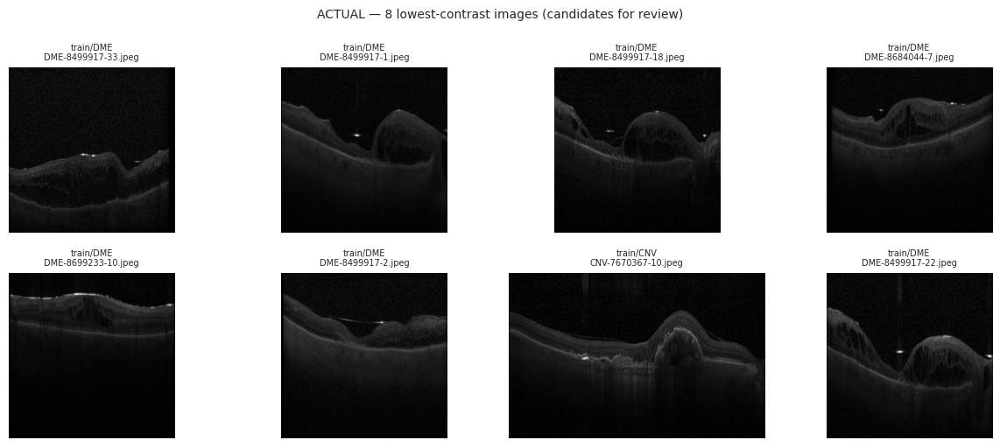

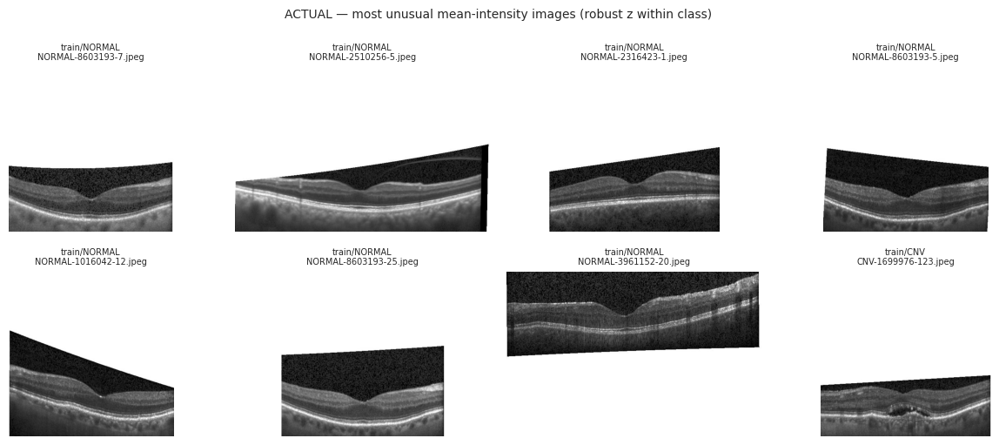

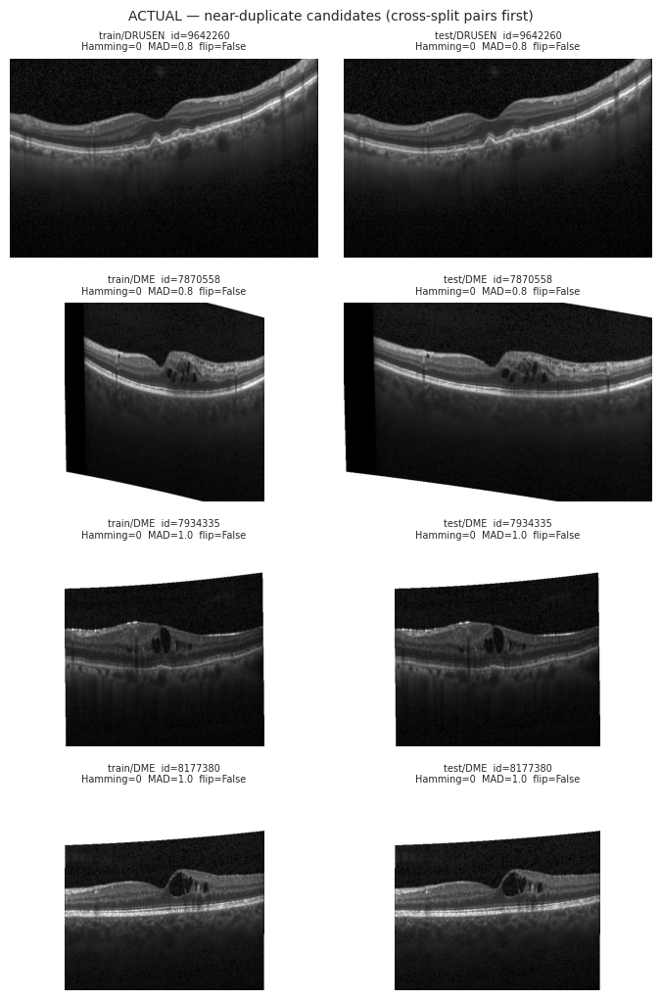

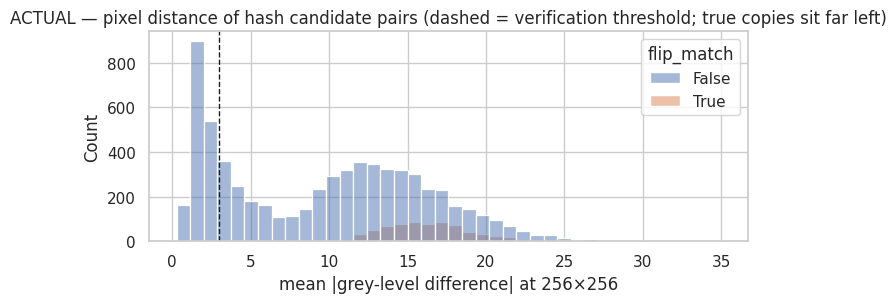

In [29]:

def show_images(df, title, ncols=4, n=8, fname=None):
    df = df.head(n)
    if df.empty:
        print(f"{title}: nothing flagged."); return
    nrows = math.ceil(len(df) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.6 * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), df.iterrows()):
        try:
            ax.imshow(Image.open(r["path"]).convert("L"), cmap="gray", vmin=0, vmax=255)
        except Exception as e:
            ax.text(0.5, 0.5, "unreadable", ha="center")
        ax.set_title(f"{r['split']}/{r['label']}\n{Path(r['path']).name[:26]}", fontsize=7)
    fig.suptitle(title, fontsize=10); fig.tight_layout()
    if fname: fig.savefig(FIG_DIR / fname, dpi=130, bbox_inches="tight")
    plt.show()

show_images(ok.sort_values("std_int").head(8), "ACTUAL — 8 lowest-contrast images (candidates for review)", fname="C_lowest_contrast_examples.png")
show_images(odd.assign(az=np.abs(rz[odd.index])).sort_values("az", ascending=False).head(8),
            "ACTUAL — most unusual mean-intensity images (robust z within class)", fname="C_intensity_outliers_examples.png")

if len(pp):
    sample = pp.assign(_v=pp["verified"].fillna(False).astype(int)).sort_values(["_v", "cross_split", "mad"], ascending=[False, False, True]).head(4)
    fig, axes = plt.subplots(len(sample), 2, figsize=(7, 2.6 * len(sample)), squeeze=False)
    for ax, (_, r) in zip(axes, sample.iterrows()):
        for k, side in enumerate(("i", "j")):
            ax[k].imshow(Image.open(r[f"path_{side}"]).convert("L"), cmap="gray"); ax[k].axis("off")
            ax[k].set_title(f"{r[f'split_{side}']}/{r[f'label_{side}']}  id={r[f'file_pid_{side}']}\nHamming={r['hamming']}  MAD={r['mad']:.1f}  flip={r['flip_match']}", fontsize=7)
    fig.suptitle("ACTUAL — near-duplicate candidates (cross-split pairs first)", fontsize=10); fig.tight_layout()
    fig.savefig(FIG_DIR / "C_near_duplicate_examples.png", dpi=130, bbox_inches="tight"); plt.show()
else:
    print("No near-duplicate candidate pairs at this threshold.")

if len(pp) and pp["mad"].notna().any():
    fig, ax = plt.subplots(figsize=(7, 3.2))
    sns.histplot(data=pp.dropna(subset=["mad"]), x="mad", hue="flip_match", bins=40, ax=ax)
    ax.axvline(VERIFY_MAD_MAX, color="k", ls="--", lw=1); ax.set_xlabel(f"mean |grey-level difference| at {VERIFY_SIZE}×{VERIFY_SIZE}")
    ax.set_title("ACTUAL — pixel distance of hash candidate pairs (dashed = verification threshold; true copies sit far left)")
    fig.tight_layout(); fig.savefig(FIG_DIR / "C_candidate_pair_MAD_hist.png", dpi=130, bbox_inches="tight"); plt.show()


In [30]:


dqd = R["dq"]

def _n(prefix):
    return next(
        (value for key, value in dqd.items() if key.startswith(prefix)),
        0
    )


c_ = [
    (
        f"Unreadable files: {_n('Unreadable')} → "
        + (
            "investigate and use defensive loading with a skip-list "
            "in the Dataset class."
            if _n("Unreadable")
            else "none found; still keep defensive image loading."
        )
    ),

    (
        f"Blank / near-blank: {_n('Blank')}; "
        f"very low contrast: {_n('Very low contrast')} → "
        "exclude only after visual confirmation; "
        "review candidates in exclusion_list.csv."
    ),

    (
        f"Exact (byte-identical) duplicates: "
        f"{_n('Exact duplicates (byte-identical files; all members counted)')} "
        f"image records in groups; "
        f"across splits: "
        f"{_n('Exact duplicates spanning more than one split')}; "
        f"with conflicting labels: "
        f"{_n('Exact duplicates with conflicting labels')} → "
        "cross-split copies may contaminate evaluation; investigate them "
        "under DG-1. Conflicting labels require label review."
    ),

    (
        f"Near-duplicates verified on pixels: "
        f"{_n('Verified near-duplicates (pixel MAD ≤ 3.0 at 256×256)')}; "
        f"flip-only: "
        f"{_n('Verified near-duplicates matching only after a horizontal flip')}; "
        f"across splits: "
        f"{_n('Verified near-duplicates spanning more than one split')} "
        f"(loose hash candidates: "
        f"{_n('Near-duplicate candidates (pHash Hamming ≤ 2, non-identical files)')}) "
        "→ inspect the pair figure and MAD histogram. Similar adjacent "
        "B-scans may be related, so consider grouping by a verified subject "
        "or volume identifier when constructing evaluation splits."
    ),

    (
        f"Filename-ID overlap between partitions: "
        f"{R.get('id_overlap', 'not available')} → "
        "inspect Section 11 and decision gate DG-1. "
        "Filename IDs are not confirmed patient IDs, so do not assume "
        "they establish patient-level leakage without verification."
    )
]

# Display or record the summary using your notebook's existing function
say("data quality, duplicates and split integrity (Section C)", c_)


** Implications for later model design — data quality, duplicates and split integrity (Section C)** *(auto-generated from the numbers above; verify before quoting)*

- Unreadable files: 0 → none found; still keep defensive image loading.
- Blank / near-blank: 0; very low contrast: 0 → exclude only after visual confirmation; review candidates in exclusion_list.csv.
- Exact (byte-identical) duplicates: 14361 image records in groups; across splits: 1331; with conflicting labels: 466 → cross-split copies may contaminate evaluation; investigate them under DG-1. Conflicting labels require label review.
- Near-duplicates verified on pixels: 2066; flip-only: 0; across splits: 384 (loose hash candidates: 9122) → inspect the pair figure and MAD histogram. Similar adjacent B-scans may be related, so consider grouping by a verified subject or volume identifier when constructing evaluation splits.
- Filename-ID overlap between partitions: {'train∩val': 21, 'train∩test': 546, 'val∩test': 1} → inspect Section 11 and decision gate DG-1. Filename IDs are not confirmed patient IDs, so do not assume they establish patient-level leakage without verification.

ACTUAL — class counts:


label,CNV,DME,DRUSEN,NORMAL
split,,,,
test,242,242,242,242
train,37205,11348,8616,26315
val,8,8,8,8
ALL,37455,11598,8866,26565


ACTUAL — class percentages (%):


label,CNV,DME,DRUSEN,NORMAL
split,,,,
test,25.00,25.00,25.00,25.00
train,44.57,13.59,10.32,31.52
val,25.00,25.00,25.00,25.00
ALL,44.33,13.73,10.49,31.44


ACTUAL — imbalance summary:


,n_total,imbalance_ratio_max/min,majority_class,majority_share_%
split,,,,
test,968,1.000,CNV,25.000
train,83484,4.318,CNV,44.565
val,32,1.000,CNV,25.000
ALL,84484,4.225,CNV,44.334


ACTUAL — accuracy of always predicting 'CNV' (training majority class), per split:
{'test': 0.25, 'train': 0.4457, 'val': 0.25}
ILLUSTRATIVE — class weights from training counts (not applied):
{'CNV': 0.561, 'DME': 1.839, 'DRUSEN': 2.422, 'NORMAL': 0.793}


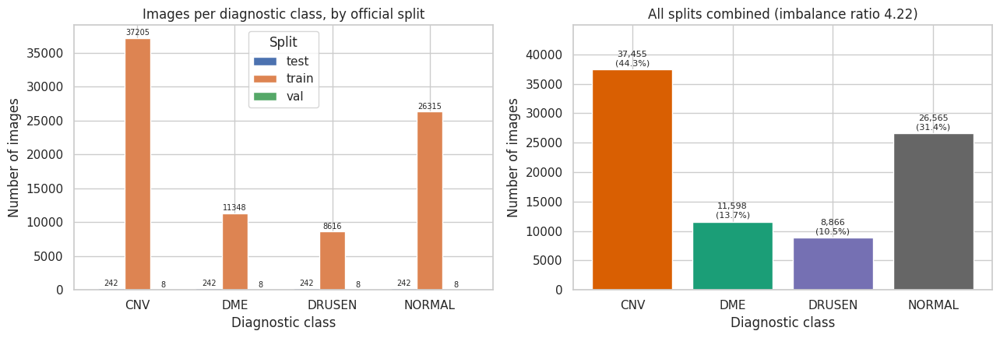


Saved output files:
/kaggle/working/task1_outputs/tables/D_class_counts.csv
/kaggle/working/task1_outputs/tables/D_class_percent.csv
/kaggle/working/task1_outputs/tables/D_imbalance_summary.csv
/kaggle/working/task1_outputs/figures/D_class_distribution.png


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


cnt = (
    meta.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=CLASSES, fill_value=0)
)


cnt.loc["ALL"] = cnt.sum(axis=0)


row_totals = cnt.sum(axis=1).replace(0, np.nan)
pct = cnt.div(row_totals, axis=0) * 100


bal = pd.DataFrame({
    "n_total": cnt.sum(axis=1),
    "imbalance_ratio_max/min": (
        cnt.max(axis=1) /
        cnt.min(axis=1).replace(0, np.nan)
    ),
    "majority_class": cnt.idxmax(axis=1),
    "majority_share_%": pct.max(axis=1)
})

print("ACTUAL — class counts:")
display(cnt)

print("ACTUAL — class percentages (%):")
display(pct.round(2))

print("ACTUAL — imbalance summary:")
display(bal.round(3))

# Save tables
cnt.to_csv(TAB_DIR / "D_class_counts.csv")
pct.round(3).to_csv(TAB_DIR / "D_class_percent.csv")
bal.to_csv(TAB_DIR / "D_imbalance_summary.csv")



if "train" in cnt.index and cnt.loc["train"].sum() > 0:

    train_counts = cnt.loc["train", CLASSES]
    maj = train_counts.idxmax()

    base = {
        split: float(cnt.loc[split, maj] / cnt.loc[split].sum())
        for split in cnt.index
        if split != "ALL" and cnt.loc[split].sum() > 0
    }

    print(
        f"ACTUAL — accuracy of always predicting '{maj}' "
        "(training majority class), per split:"
    )
    print({k: round(v, 4) for k, v in base.items()})

    R["majority_baseline_acc"] = base

    
    
    ntr = train_counts
    n_classes = len(CLASSES)

    w = (
        ntr.sum() /
        (n_classes * ntr.replace(0, np.nan))
    ).round(3)

    print(
        "ILLUSTRATIVE — class weights from training counts "
        "(not applied):"
    )
    print(w.to_dict())

    R["illustrative_class_weights_from_train"] = w.to_dict()

else:
    print(
        "WARNING — no non-empty training split found; "
        "majority baseline and class weights were not calculated."
    )


plot_cnt = cnt.drop(index="ALL")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))


plot_cnt.T.plot(
    kind="bar",
    ax=axes[0],
    width=0.8
)

axes[0].set_title("Images per diagnostic class, by official split")
axes[0].set_xlabel("Diagnostic class")
axes[0].set_ylabel("Number of images")
axes[0].legend(title="Split")
axes[0].tick_params(axis="x", rotation=0)

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%d",
        fontsize=7,
        padding=1
    )


class_counts = cnt.loc["ALL", CLASSES]
class_percentages = pct.loc["ALL", CLASSES]

bars = axes[1].bar(
    CLASSES,
    class_counts,
    color=[CLASS_COLORS[c] for c in CLASSES]
)

labels = [
    f"{int(v):,}\n({p:.1f}%)"
    for v, p in zip(class_counts, class_percentages)
]

axes[1].bar_label(
    bars,
    labels=labels,
    fontsize=8,
    padding=2
)

overall_ratio = bal.loc["ALL", "imbalance_ratio_max/min"]

axes[1].set_title(
    f"All splits combined (imbalance ratio {overall_ratio:.2f})"
)
axes[1].set_xlabel("Diagnostic class")
axes[1].set_ylabel("Number of images")
axes[1].set_ylim(0, class_counts.max() * 1.2)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "D_class_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


print("\nSaved output files:")
print(TAB_DIR / "D_class_counts.csv")
print(TAB_DIR / "D_class_percent.csv")
print(TAB_DIR / "D_imbalance_summary.csv")
print(FIG_DIR / "D_class_distribution.png")


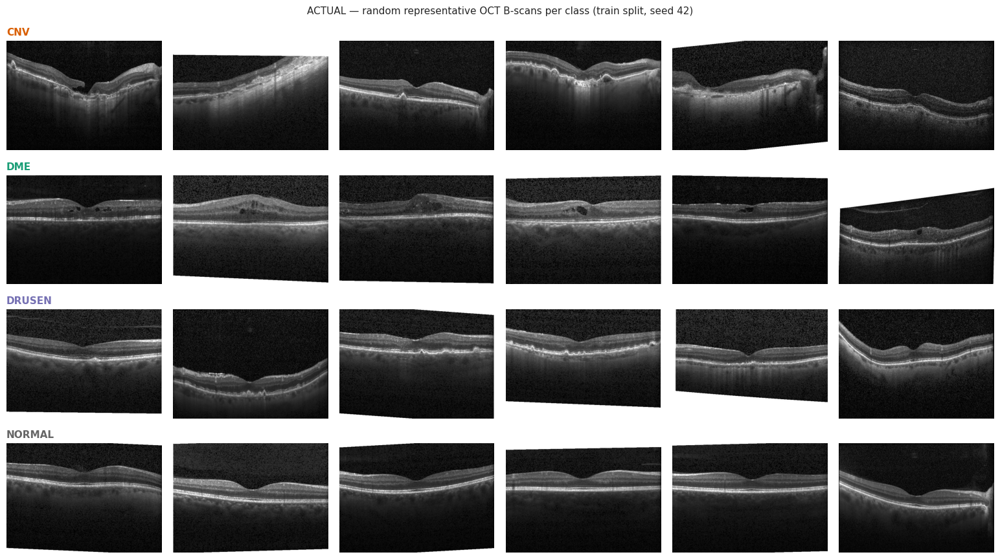

In [32]:

src = ok[ok["split"] == "train"] if (ok["split"] == "train").any() else ok
N_PER = 6
fig, axes = plt.subplots(len(CLASSES), N_PER, figsize=(2.6 * N_PER, 2.2 * len(CLASSES)), squeeze=False)
for r_i, c in enumerate(CLASSES):
    g = src[src["label"] == c]
    pick = g.sample(min(N_PER, len(g)), random_state=SEED) if len(g) else g
    for c_i in range(N_PER):
        ax = axes[r_i, c_i]; ax.axis("off")
        if c_i < len(pick):
            row = pick.iloc[c_i]
            ax.imshow(Image.open(row["path"]).convert("L"), cmap="gray", vmin=0, vmax=255, aspect="auto")
            if c_i == 0: ax.set_title(c, loc="left", fontsize=11, color=CLASS_COLORS[c], fontweight="bold")
fig.suptitle("ACTUAL — random representative OCT B-scans per class (train split, seed 42)", fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "E_representative_grid.png", dpi=140, bbox_inches="tight"); plt.show()

## Visual Interpretation & Comparative Analysis

### 1. Layer Thickness & Retinal Architecture
* **NORMAL:** Exhibits clear, uniform, and well-preserved retinal layer architecture with a smooth, distinct foveal depression (foveal pit)[cite: 1]. The overall thickness across the retina remains highly consistent and undisturbed[cite: 1].
* **CNV (Choroidal Neovascularization):** Displays marked layer distortion and localized, highly irregular retinal elevation/thickening[cite: 1]. The normal layered anatomical structure is significantly disrupted, with noticeable subretinal/intraretinal elevation and subretinal tissue masses[cite: 1].
* **DME (Diabetic Macular Edema):** Shows generalized to diffuse neurosensory retinal thickening[cite: 1]. The foveal contour is frequently flattened or loss of depression due to widespread cystic expansion[cite: 1].
* **DRUSEN:** Retinal thickness is generally preserved in intact areas, but displays characteristic localized, wavy, undulating elevations along the Retinal Pigment Epithelium (RPE) / Bruch’s membrane layer[cite: 1].

---

### 2. Fluid Spaces (Hyporeflective Cavities)
* **NORMAL:** Entirely devoid of intraretinal or subretinal hyporeflective fluid accumulation[cite: 1].
* **CNV:** Shows distinct hyporeflective subretinal and intraretinal fluid pockets associated with hyperreflective neovascular membrane structures[cite: 1].
* **DME:** Prominently features multiple round to oval dark hyporeflective intraretinal cystic spaces (cystoid macular edema) scattered within the inner and outer retinal layers[cite: 1].
* **DRUSEN:** Lacks large intraretinal cystoid fluid spaces, though subtle sub-RPE clear spaces created by discrete drusen deposits elevation are present[cite: 1].

---

### 3. Deposits & Sub-RPE Hyperreflectivity
* **NORMAL:** Demonstrates a clean, smooth, continuous hyperreflective line corresponding to the RPE layer without sub-RPE nodular deposits or focal disruptions[cite: 1].
* **CNV:** Features large, complex hyperreflective complex regions in the subretinal space, often accompanied by structural shadowing beneath[cite: 1].
* **DME:** Focuses predominantly on intraretinal fluid cavities rather than major sub-RPE solid deposits, though minor hyperreflective foci may occasionally be seen inside retinal layers[cite: 1].
* **DRUSEN:** Uniquely characterized by distinct dome-shaped or convex nodular sub-RPE deposits (drusen) causing repetitive bump-like elevations along the hyperreflective RPE line[cite: 1].

---

### 4. Image Framing, Borders, Brightness & Artifacts
* **Framing & Tilting:** Across all four classes (CNV, DME, DRUSEN, NORMAL), several B-scans show systematic tilt, irregular dark borders (black wedge-shaped boundaries resulting from registration/alignment or scan rotation), and slight variations in vertical centering[cite: 1].
* **Contrast & Brightness:** CNV and DME images exhibit higher variation in signal attenuation and background contrast—partially caused by fluid-induced shadow effects and tissue elevation—compared to the more uniform contrast seen in NORMAL scans[cite: 1].
* **Borders & Dimensions:** All images share uniform visual aspect ratios within the grid, but individual scan cropping/padding varies slightly across classes due to differences in scanner alignment and scan extent[cite: 1].

---

> **Important Diagnostic Note:** The visual patterns described above (such as layer thickness, fluid cavities, and RPE elevations) are visual characteristics observed across representative B-scan samples[cite: 1]. **Visual inspection alone does not establish a formal clinical diagnosis**, as expert clinical correlation, full volumetric scans, and multimodal imaging are required for accurate clinical assessment.

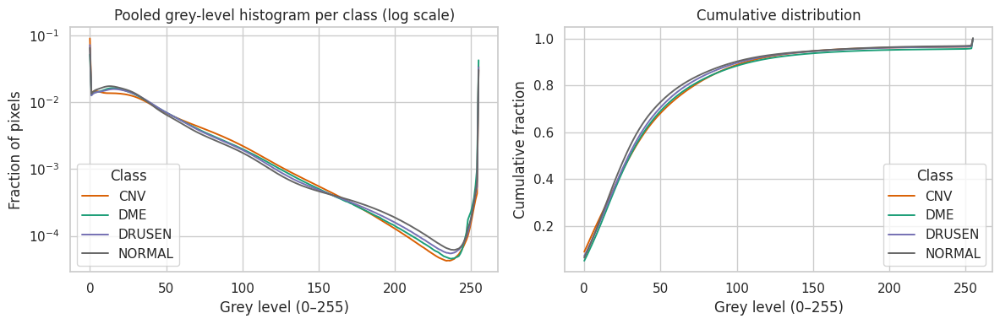

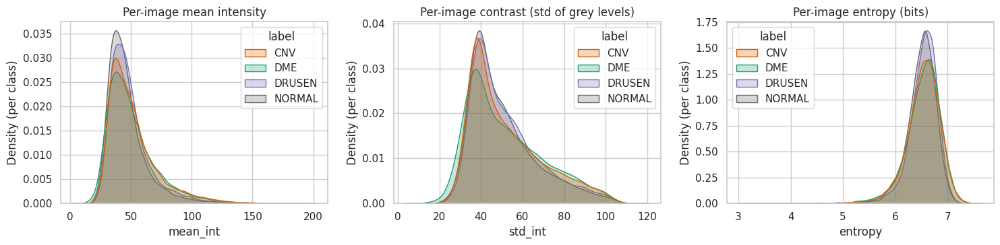

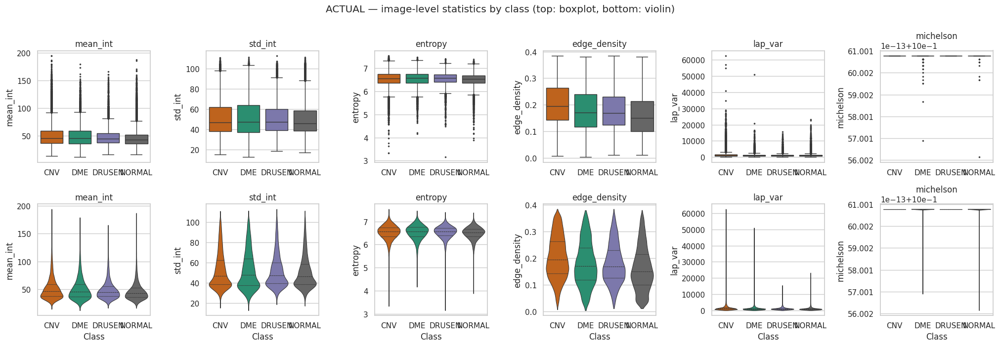

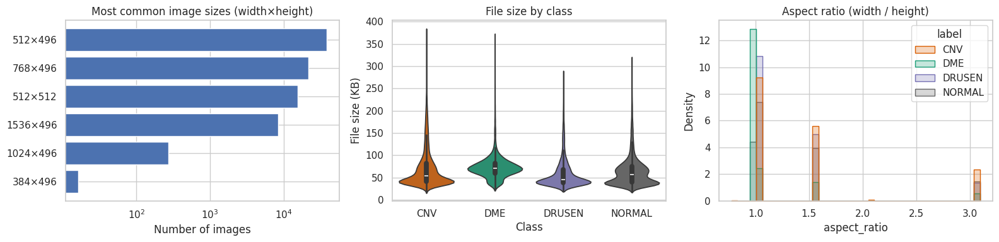

ACTUAL — Kruskal–Wallis across the four classes (ε² ≈ share of rank variance explained by class; rough guide: <0.01 negligible, 0.01–0.06 small, 0.06–0.14 medium, >0.14 large):


,feature,H,p_value_(anti-conservative),epsilon_squared,n_images
10,height,35966.7122,0.0,0.4257,84484
11,aspect_ratio,18839.7722,0.0,0.2230,84484
9,width,4896.2113,0.0,0.0579,84484
5,edge_density,4155.5176,0.0,0.0492,84484
12,file_kb,3268.6381,0.0,0.0387,84484
6,lap_var,3253.9639,0.0,0.0385,84484
7,frac_zero,2462.7109,0.0,0.0291,84484
1,median_int,2335.8760,0.0,0.0276,84484
0,mean_int,942.7615,0.0,0.0111,84484
4,entropy,342.2675,0.0,0.0040,84484


In [33]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c in CLASSES:
    h = sum((v for (s, lab), v in HIST.items() if lab == c), start=np.zeros(256, dtype=np.int64)).astype(float)
    if h.sum() == 0: continue
    p = h / h.sum()
    axes[0].plot(np.arange(256), p, label=c, color=CLASS_COLORS[c], lw=1.4)
    axes[1].plot(np.arange(256), np.cumsum(p), label=c, color=CLASS_COLORS[c], lw=1.4)
axes[0].set_yscale("log"); axes[0].set_title("Pooled grey-level histogram per class (log scale)")
axes[0].set_xlabel("Grey level (0–255)"); axes[0].set_ylabel("Fraction of pixels")
axes[1].set_title("Cumulative distribution"); axes[1].set_xlabel("Grey level (0–255)"); axes[1].set_ylabel("Cumulative fraction")
for ax in axes: ax.legend(title="Class")
fig.tight_layout(); fig.savefig(FIG_DIR / "E_pixel_histograms_by_class.png", dpi=140, bbox_inches="tight"); plt.show()


fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (f, t) in zip(axes, [("mean_int", "Per-image mean intensity"), ("std_int", "Per-image contrast (std of grey levels)"), ("entropy", "Per-image entropy (bits)")]):
    sns.kdeplot(data=ok, x=f, hue="label", hue_order=CLASSES, palette=CLASS_COLORS, common_norm=False, fill=True, alpha=0.25, ax=ax, warn_singular=False)
    ax.set_title(t); ax.set_xlabel(f); ax.set_ylabel("Density (per class)")
fig.tight_layout(); fig.savefig(FIG_DIR / "E_intensity_contrast_entropy_kde.png", dpi=140, bbox_inches="tight"); plt.show()


feats = ["mean_int", "std_int", "entropy", "edge_density", "lap_var", "michelson"]
fig, axes = plt.subplots(2, len(feats), figsize=(3.4 * len(feats), 7))
for k, f in enumerate(feats):
    sns.boxplot(data=ok, x="label", y=f, order=CLASSES, palette=CLASS_COLORS, ax=axes[0, k], fliersize=1.5)
    sns.violinplot(data=ok, x="label", y=f, order=CLASSES, palette=CLASS_COLORS, ax=axes[1, k], cut=0, inner="quartile", linewidth=0.8)
    axes[0, k].set_title(f); axes[1, k].set_title(f); axes[0, k].set_xlabel(""); axes[1, k].set_xlabel("Class")
fig.suptitle("ACTUAL — image-level statistics by class (top: boxplot, bottom: violin)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "E_box_violin_by_class.png", dpi=140, bbox_inches="tight"); plt.show()


fig, axes = plt.subplots(1, 3, figsize=(16, 4))
top = size_counts.head(10)
axes[0].barh([f"{w}×{h}" for w, h in top.index][::-1], top.values[::-1], color="#4c72b0")
axes[0].set_title("Most common image sizes (width×height)"); axes[0].set_xlabel("Number of images"); axes[0].set_xscale("log")
sns.violinplot(data=ok, x="label", y="file_kb", order=CLASSES, palette=CLASS_COLORS, ax=axes[1], cut=0)
axes[1].set_title("File size by class"); axes[1].set_ylabel("File size (KB)"); axes[1].set_xlabel("Class")
sns.histplot(data=ok, x="aspect_ratio", hue="label", hue_order=CLASSES, palette=CLASS_COLORS, element="step", stat="density", common_norm=False, ax=axes[2], bins=40)
axes[2].set_title("Aspect ratio (width / height)")
fig.tight_layout(); fig.savefig(FIG_DIR / "E_dimensions_filesize.png", dpi=140, bbox_inches="tight"); plt.show()


kw_rows = []
for f in ["mean_int", "median_int", "std_int", "michelson", "entropy", "edge_density", "lap_var", "frac_zero", "frac_255", "width", "height", "aspect_ratio", "file_kb"]:
    groups = [g[f].dropna().to_numpy() for _, g in ok.groupby("label") if g[f].notna().sum() > 1]
    if len(groups) < 2 or all(np.ptp(np.concatenate(groups)) == 0 for _ in [0]):
        continue
    H, p = stats.kruskal(*groups); n = sum(len(g) for g in groups); k = len(groups)
    kw_rows.append({"feature": f, "H": H, "p_value_(anti-conservative)": p, "epsilon_squared": (H - k + 1) / (n - k), "n_images": n})
kw = pd.DataFrame(kw_rows).sort_values("epsilon_squared", ascending=False)
print("ACTUAL — Kruskal–Wallis across the four classes (ε² ≈ share of rank variance explained by class; rough guide: <0.01 negligible, 0.01–0.06 small, 0.06–0.14 medium, >0.14 large):")
display(kw.round(4)); kw.to_csv(TAB_DIR / "E_kruskal_by_class.csv", index=False)
R["kruskal_epsilon2"] = kw.set_index("feature")["epsilon_squared"].round(4).to_dict()

Dropped constant features (correlation undefined): ['min_int', 'max_int', 'michelson']


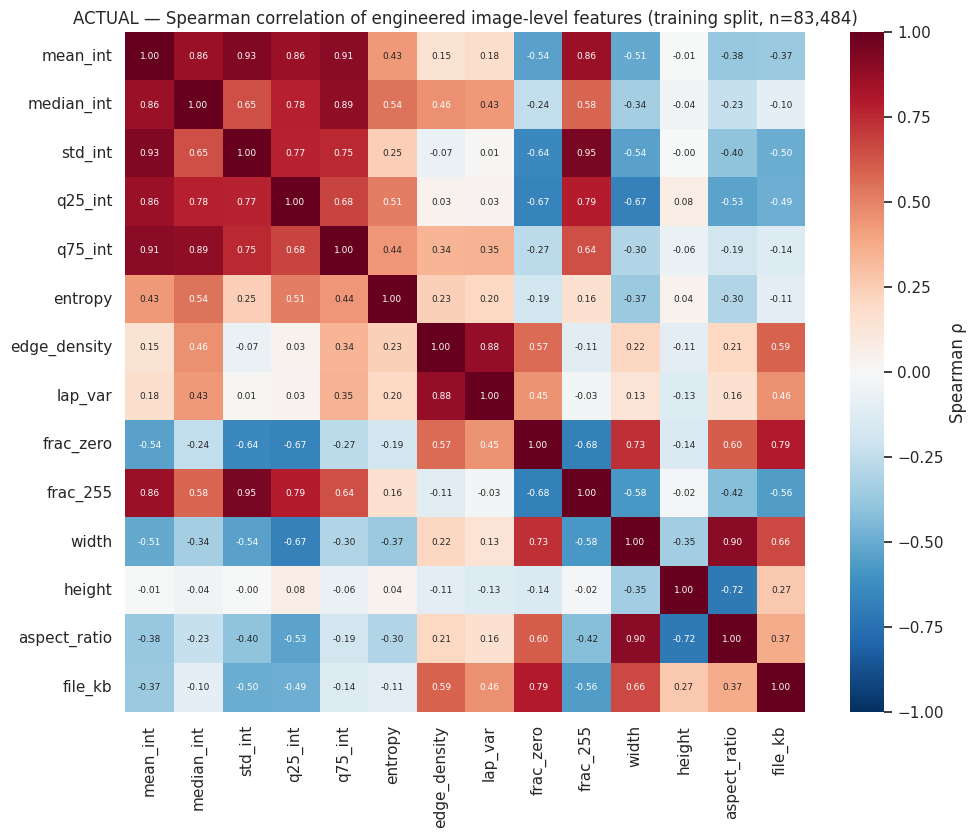

ACTUAL — 4 feature pairs with |ρ| ≥ 0.90 (candidate redundancy):


,feature_a,feature_b,spearman_rho
0,std_int,frac_255,0.951
1,mean_int,std_int,0.926
2,mean_int,q75_int,0.906
3,width,aspect_ratio,0.904



Association with the diagnostic label (epsilon-squared from Section E; descriptive only).


,feature,epsilon_squared
0,height,0.4257
1,aspect_ratio,0.2230
2,width,0.0579
3,edge_density,0.0492
4,file_kb,0.0387
5,lap_var,0.0385
6,frac_zero,0.0291
7,median_int,0.0276
8,mean_int,0.0111
9,entropy,0.0040



Saved outputs:
/kaggle/working/task1_outputs/tables/F_spearman_correlation.csv
/kaggle/working/task1_outputs/tables/F_redundant_pairs.csv
/kaggle/working/task1_outputs/figures/F_correlation_heatmap.png


In [34]:



import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown


CORR_FEATURES = [
    "mean_int", "median_int", "std_int", "min_int", "max_int",
    "q25_int", "q75_int", "michelson", "entropy", "edge_density",
    "lap_var", "frac_zero", "frac_255", "width", "height",
    "aspect_ratio", "file_kb"
]


missing_cols = [
    c for c in ["split"] + CORR_FEATURES
    if c not in ok.columns
]

if missing_cols:
    raise KeyError(f"Missing required columns in ok: {missing_cols}")


ctrain = ok[ok["split"].eq("train")].copy()

if ctrain.empty:
    raise ValueError(
        "No training rows found in ok. "
        "Check the split column and metadata."
    )

Xc = ctrain[CORR_FEATURES].copy()


Xc = Xc.apply(pd.to_numeric, errors="coerce")
Xc = Xc.replace([np.inf, -np.inf], np.nan)


const = [
    c for c in Xc.columns
    if Xc[c].nunique(dropna=True) <= 1
    or Xc[c].value_counts(normalize=True).iloc[0] > 0.99      # v2: near-constant (max_int, michelson): correlations are artefacts
]

if const:
    print("Dropped constant features (correlation undefined):", const)
    Xc = Xc.drop(columns=const)


all_missing = Xc.columns[Xc.isna().all()].tolist()

if all_missing:
    print("Dropped entirely missing features:", all_missing)
    Xc = Xc.drop(columns=all_missing)

if Xc.shape[1] < 2:
    raise ValueError(
        "At least two usable features are required for correlation analysis."
    )




corr = Xc.corr(method="spearman", min_periods=2)

fig, ax = plt.subplots(figsize=(10.5, 8.5))

sns.heatmap(
    corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 6.5},
    square=True,
    cbar_kws={"label": "Spearman ρ"},
    ax=ax
)

ax.set_title(
    "ACTUAL — Spearman correlation of engineered image-level "
    f"features (training split, n={len(Xc):,})"
)

fig.tight_layout()
fig.savefig(
    FIG_DIR / "F_correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


pairs_hi = [
    (a, b, corr.loc[a, b])
    for a, b in itertools.combinations(corr.columns, 2)
    if pd.notna(corr.loc[a, b])
    and abs(corr.loc[a, b]) >= 0.90
]

red = pd.DataFrame(
    pairs_hi,
    columns=["feature_a", "feature_b", "spearman_rho"]
)

if not red.empty:
    red = red.reindex(
        red["spearman_rho"].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)

print(
    f"ACTUAL — {len(red)} feature pairs with "
    "|ρ| ≥ 0.90 (candidate redundancy):"
)

if red.empty:
    display(Markdown("*No pairs met the |ρ| ≥ 0.90 threshold.*"))
else:
    display(red.round(3))

# Save correlation tables
corr.to_csv(TAB_DIR / "F_spearman_correlation.csv")
red.to_csv(TAB_DIR / "F_redundant_pairs.csv", index=False)

R["redundant_pairs"] = [
    (a, b, round(float(r), 3))
    for a, b, r in pairs_hi
]


print(
    "\nAssociation with the diagnostic label "
    "(epsilon-squared from Section E; descriptive only)."
)

if "kw" in globals() and {
    "feature", "epsilon_squared"
}.issubset(kw.columns):

    display(
        kw[["feature", "epsilon_squared"]]
        .round(4)
        .reset_index(drop=True)
    )

else:
    print(
        "Section E association results are unavailable or have a "
        "different column structure. Run/check the Section E results "
        "before reporting feature-label associations."
    )

print("\nSaved outputs:")
print(TAB_DIR / "F_spearman_correlation.csv")
print(TAB_DIR / "F_redundant_pairs.csv")
print(FIG_DIR / "F_correlation_heatmap.png")


In [35]:
e_ = []
kwd = R["kruskal_epsilon2"]
acq = {f: kwd[f] for f in ("width", "height", "aspect_ratio", "file_kb") if f in kwd}
flag = {f: v for f, v in acq.items() if v >= 0.06}
if flag:
    e_.append(f"Acquisition-related features differ by class (ε² ≥ 0.06): {flag} → a network could use image size/file size as a shortcut. Plan: identical resize for all models and a metadata-only sanity baseline (width, height, file size → classifier) in Task 2.")
else:
    e_.append(f"Image size / file size are weakly associated with class (ε²: {acq}) → low shortcut risk from dimensions; intensity-based acquisition effects remain possible.")
e_.append(f"Strongest class associations among image-level features (ε²): {sorted(kwd.items(), key=lambda kv: -kv[1])[:3]} → descriptive only; centre/device differences can produce these without any disease signal.")
if R["redundant_pairs"]:
    e_.append(f"{len(R['redundant_pairs'])} feature pairs with |ρ| ≥ 0.90 → keep one of each pair in any classical-feature baseline.")
say("distributions and correlations (Sections E–F)", e_)

** Implications for later model design — distributions and correlations (Sections E–F)** *(auto-generated from the numbers above; verify before quoting)*

- Acquisition-related features differ by class (ε² ≥ 0.06): {'height': 0.4257, 'aspect_ratio': 0.223} → a network could use image size/file size as a shortcut. Plan: identical resize for all models and a metadata-only sanity baseline (width, height, file size → classifier) in Task 2.
- Strongest class associations among image-level features (ε²): [('height', 0.4257), ('aspect_ratio', 0.223), ('width', 0.0579)] → descriptive only; centre/device differences can produce these without any disease signal.
- 4 feature pairs with |ρ| ≥ 0.90 → keep one of each pair in any classical-feature baseline.

Subset for dimensionality reduction: 8,000 train images (2,000 per class); t-SNE uses 4,000


thumbnails:   0%|          | 0/8000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


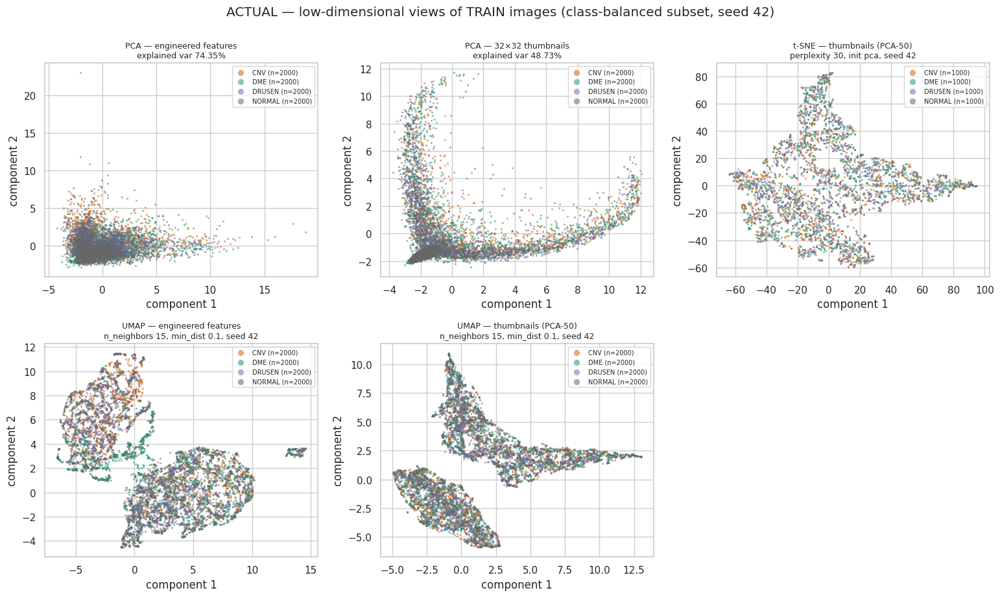

Descriptive silhouette scores of the 2-D views (range −1…1; ≈0 means heavy overlap; NOT a measure of classifier accuracy):


,"silhouette (2-D, by class)"
PCA — engineered features,-0.054
PCA — 32×32 thumbnails,-0.057
t-SNE — thumbnails (PCA-50),-0.028
UMAP — engineered features,-0.039
UMAP — thumbnails (PCA-50),-0.027


Thumbnail PCA-50 explains 92.4% of variance; first 5 components: [0.3179999887943268, 0.17000000178813934, 0.07900000363588333, 0.05999999865889549, 0.035999998450279236]


In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

pool = ok[ok["split"] == "train"] if (ok["split"] == "train").any() else ok
per_cls = min(UMAP_N // len(CLASSES), int(pool["label"].value_counts().min()))
sub = pd.concat([g.sample(per_cls, random_state=SEED) for _, g in pool.groupby("label")]).sample(frac=1, random_state=SEED).reset_index(drop=True)
per_cls_t = min(TSNE_N // len(CLASSES), per_cls)
sub["in_tsne"] = sub.groupby("label").cumcount() < per_cls_t
print(f"Subset for dimensionality reduction: {len(sub):,} train images ({per_cls:,} per class); t-SNE uses {int(sub['in_tsne'].sum()):,}")

def thumb(path, s=THUMB):
    a = np.asarray(Image.open(path).convert("L"))
    return cv2.resize(a, (s, s), interpolation=cv2.INTER_AREA).astype(np.float32).ravel() / 255.0
X_thumb = np.stack([thumb(p) for p in tqdm(sub["path"], desc="thumbnails")])

DR_EXCLUDE = ("width", "height", "aspect_ratio", "file_kb", "max_int", "michelson")   # v2: geometry/file-size and near-constant features would make the views follow acquisition, not appearance
eng_cols = [c for c in ENG_FEATURES if sub[c].nunique() > 1 and c not in DR_EXCLUDE]
R["dr_engineered_features"] = eng_cols
X_eng = StandardScaler().fit_transform(sub[eng_cols].to_numpy())          # scaler fitted on this TRAIN subset only
X_thumb_c = X_thumb - X_thumb.mean(axis=0)
pca_thumb50 = PCA(n_components=min(50, X_thumb.shape[1], len(sub) - 1), random_state=SEED).fit(X_thumb_c)
Z_thumb50 = pca_thumb50.transform(X_thumb_c)

emb = {}   # name -> (2D array, mask of rows used, description)
p_eng = PCA(n_components=2, random_state=SEED).fit(X_eng); emb["PCA — engineered features"] = (p_eng.transform(X_eng), np.ones(len(sub), bool), f"explained var {p_eng.explained_variance_ratio_.sum():.2%}")
p_th = PCA(n_components=2, random_state=SEED).fit(X_thumb_c); emb[f"PCA — {THUMB}×{THUMB} thumbnails"] = (p_th.transform(X_thumb_c), np.ones(len(sub), bool), f"explained var {p_th.explained_variance_ratio_.sum():.2%}")
mt = sub["in_tsne"].to_numpy()
emb["t-SNE — thumbnails (PCA-50)"] = (TSNE(**TSNE_PARAMS).fit_transform(Z_thumb50[mt]), mt, f"perplexity {TSNE_PARAMS['perplexity']}, init pca, seed {SEED}")
if umap is not None:
    emb["UMAP — engineered features"] = (umap.UMAP(**UMAP_PARAMS).fit_transform(X_eng), np.ones(len(sub), bool), f"n_neighbors {UMAP_PARAMS['n_neighbors']}, min_dist {UMAP_PARAMS['min_dist']}, seed {SEED}")
    emb["UMAP — thumbnails (PCA-50)"] = (umap.UMAP(**UMAP_PARAMS).fit_transform(Z_thumb50), np.ones(len(sub), bool), f"n_neighbors {UMAP_PARAMS['n_neighbors']}, min_dist {UMAP_PARAMS['min_dist']}, seed {SEED}")
else:
    print("UMAP skipped (umap-learn not installed).")

if USE_EFFNET_EMBEDDINGS:
    try:
        import torch, torchvision
        from torchvision import models, transforms
        wts = models.EfficientNet_B0_Weights.IMAGENET1K_V1
        net = models.efficientnet_b0(weights=wts).eval(); net.classifier = torch.nn.Identity()
        prep = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                   transforms.Normalize(wts.transforms().mean, wts.transforms().std)])
        feats = []
        with torch.no_grad():
            for i in tqdm(range(0, len(sub), 64), desc="EfficientNet-B0 embeddings"):
                batch = torch.stack([prep(Image.open(p).convert("RGB")) for p in sub["path"].iloc[i:i + 64]])
                feats.append(net(batch).numpy())
        E = np.concatenate(feats)
        if umap is not None: emb["UMAP — EfficientNet-B0 embeddings (ImageNet weights)"] = (umap.UMAP(**UMAP_PARAMS).fit_transform(E), np.ones(len(sub), bool), "1280-d, frozen, no fine-tuning")
    except Exception as e:
        print("EfficientNet-B0 embeddings skipped:", repr(e)[:200])

n_p = len(emb); ncol = 3; nrow = math.ceil(n_p / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 4.6 * nrow), squeeze=False)
for ax in axes.ravel(): ax.axis("off")
sil = {}
for ax, (name, (Z, mask, note)) in zip(axes.ravel(), emb.items()):
    ax.axis("on"); lab = sub.loc[mask, "label"].to_numpy()
    for c in CLASSES:
        m = lab == c
        ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.55, c=CLASS_COLORS[c], label=f"{c} (n={int(m.sum())})", linewidths=0)
    ax.set_title(f"{name}\n{note}", fontsize=9); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    ax.legend(markerscale=3, fontsize=7, loc="best")
    try: sil[name] = float(silhouette_score(Z, lab))
    except Exception: sil[name] = float("nan")
fig.suptitle(f"ACTUAL — low-dimensional views of TRAIN images (class-balanced subset, seed {SEED})", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "G_dimensionality_reduction.png", dpi=140, bbox_inches="tight"); plt.show()

print("Descriptive silhouette scores of the 2-D views (range −1…1; ≈0 means heavy overlap; NOT a measure of classifier accuracy):")
display(pd.Series(sil, name="silhouette (2-D, by class)").round(3).to_frame())
ev = pca_thumb50.explained_variance_ratio_
print(f"Thumbnail PCA-50 explains {ev.sum():.1%} of variance; first 5 components: {np.round(ev[:5], 3).tolist()}")
R["silhouette_2d"] = {k: round(v, 4) for k, v in sil.items()}

DR = sub[["path", "filename", "split", "label", "file_pid"]].copy()
for name, (Z, mask, _) in emb.items():
    col = np.full((len(sub), 2), np.nan); col[mask] = Z
    key = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    DR[f"{key}_1"], DR[f"{key}_2"] = col[:, 0], col[:, 1]
DR.to_csv(TAB_DIR / "G_embeddings_2d.csv.gz", index=False)
import sklearn
json.dump({"seed": SEED, "n_subset": int(len(sub)), "per_class": int(per_cls), "tsne_n": int(mt.sum()), "thumb_size": THUMB,
           "tsne_params": {k: str(v) for k, v in TSNE_PARAMS.items()}, "umap_params": {k: str(v) for k, v in UMAP_PARAMS.items()},
           "engineered_features": eng_cols, "effnet_embeddings_used": bool(USE_EFFNET_EMBEDDINGS),
           "versions": {"sklearn": sklearn.__version__, "umap": getattr(umap, "__version__", "missing"), "numpy": np.__version__}},
          open(TAB_DIR / "G_dr_params.json", "w"), indent=2)

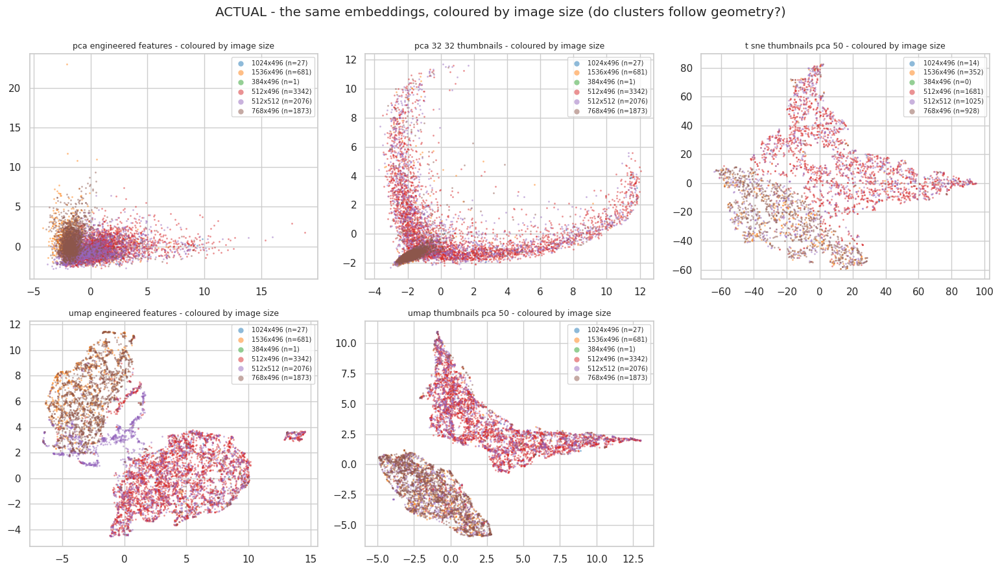

Class mix inside each image size for the plotted TRAIN subset (%):


label,CNV,DME,DRUSEN,NORMAL
size,,,,
1024x496,48.1,11.1,25.9,14.8
1536x496,38.2,10.3,28.0,23.5
384x496,0.0,0.0,0.0,100.0
512x496,31.2,7.5,36.3,25.0
512x512,0.0,73.9,0.0,26.1
768x496,36.5,7.6,31.4,24.4


In [37]:

sz_df = ok[["path", "width", "height"]].copy()
sz_df["size"] = sz_df["width"].astype(int).astype(str) + "x" + sz_df["height"].astype(int).astype(str)
DRs = DR.merge(sz_df[["path", "size"]], on="path", how="left")
emb_keys = [c[:-2] for c in DR.columns if c.endswith("_1")]
sizes = sorted(DRs["size"].dropna().unique()); pal = dict(zip(sizes, sns.color_palette("tab10", len(sizes))))
ncol = 3; nrow = math.ceil(len(emb_keys) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 4.4 * nrow), squeeze=False)
for ax in axes.ravel(): ax.axis("off")
for ax, key in zip(axes.ravel(), emb_keys):
    d = DRs.dropna(subset=[f"{key}_1"]); ax.axis("on")
    for s in sizes:
        m = d["size"] == s
        ax.scatter(d.loc[m, f"{key}_1"], d.loc[m, f"{key}_2"], s=4, alpha=0.5, color=pal[s], label=f"{s} (n={int(m.sum())})", linewidths=0)
    ax.set_title(key.replace("_", " ") + " - coloured by image size", fontsize=9); ax.legend(markerscale=3, fontsize=7)
fig.suptitle("ACTUAL - the same embeddings, coloured by image size (do clusters follow geometry?)", y=1.0); fig.tight_layout()
fig.savefig(FIG_DIR / "G_embeddings_coloured_by_size.png", dpi=140, bbox_inches="tight"); plt.show()
print("Class mix inside each image size for the plotted TRAIN subset (%):")
display((pd.crosstab(DRs["size"], DRs["label"], normalize="index") * 100).round(1))

**Interpretation of dimensionality-reduction views:** The PCA, t-SNE, and UMAP visualizations show substantial overlap among CNV, DME, DRUSEN, and NORMAL rather than clearly separated, class-pure clusters. The engineered-feature representations and resized-image representations do not show strong class separation in two dimensions, which is consistent with the low silhouette scores. No representation demonstrates clearly separated clusters for all four classes. In the size-coloured visualization, image size appears to be a potential source of structure in the feature space, suggesting that some visual groupings may reflect differences in image dimensions or acquisition/preprocessing rather than diagnosis alone.

The class distribution within image sizes supports further investigation of this possibility. For example, all images in the plotted TRAIN subset with size 384×496 are NORMAL, while 512×512 images are predominantly DME (73.9%). In contrast, 512×496 images contain a mixture of all four classes. These patterns suggest that image dimensions may be associated with class labels in this subset and could provide a shortcut for a model. However, the table alone does not establish why these associations occur or whether they generalize to the full dataset. Image dimensions and resizing should therefore be handled consistently, and a metadata-only baseline should be considered to test whether image size alone predicts the diagnosis.

These plots are exploratory: low silhouette scores and overlapping two-dimensional projections do not demonstrate that a CNN cannot learn useful diagnostic features, while visible clusters do not prove that a CNN will achieve good classification performance. Model performance must be established through appropriately separated training and evaluation data.

In [38]:
sil_ = R["silhouette_2d"]; g_ = []
g_.append(f"2-D silhouette scores by class: {sil_} (≈ 0 means heavy overlap) → " + ("low values are expected for hand-crafted statistics and raw thumbnails; this says nothing about what a CNN can learn." if max(sil_.values()) < 0.25 else "some separation exists even in simple views → a clear signal is present; recolour the plot by width/file size to check it is not acquisition-driven."))
g_.append("t-SNE/UMAP distances, cluster sizes and gaps are not quantitative; never quote a picture as evidence of classification accuracy.")
g_.append("All reductions used the training split only (scaler/PCA fitted on the TRAIN subset) — keep this rule for any learned preprocessing later.")
say("dimensionality reduction ", g_)

** Implications for later model design — dimensionality reduction ** *(auto-generated from the numbers above; verify before quoting)*

- 2-D silhouette scores by class: {'PCA — engineered features': -0.0537, 'PCA — 32×32 thumbnails': -0.0567, 't-SNE — thumbnails (PCA-50)': -0.0283, 'UMAP — engineered features': -0.0391, 'UMAP — thumbnails (PCA-50)': -0.0269} (≈ 0 means heavy overlap) → low values are expected for hand-crafted statistics and raw thumbnails; this says nothing about what a CNN can learn.
- t-SNE/UMAP distances, cluster sizes and gaps are not quantitative; never quote a picture as evidence of classification accuracy.
- All reductions used the training split only (scaler/PCA fitted on the TRAIN subset) — keep this rule for any learned preprocessing later.

In [39]:

d1 = cnt.drop(index="ALL").reset_index().melt(id_vars="split", var_name="class", value_name="images")
f1 = px.bar(d1, x="class", y="images", color="split", barmode="group", text="images",
            category_orders={"class": CLASSES}, title="Images per diagnostic class and official split (hover for counts)",
            labels={"images": "Number of images", "class": "Diagnostic class", "split": "Split"})
f1.update_traces(textposition="outside"); f1.write_html(INT_DIR / "H1_class_distribution.html", include_plotlyjs="cdn"); f1.show()


sz = ok.groupby(["width", "height", "label"]).size().reset_index(name="images")
f2 = px.scatter(sz, x="width", y="height", size="images", color="label", color_discrete_map=CLASS_COLORS, size_max=40,
                title="Distinct image sizes (bubble area = number of images)", labels={"width": "Width (px)", "height": "Height (px)", "label": "Class"},
                hover_data={"images": True})
f2.write_html(INT_DIR / "H2a_image_sizes.html", include_plotlyjs="cdn"); f2.show()
samp = ok.sample(min(15000, len(ok)), random_state=SEED)
f2b = px.scatter(samp, x="mean_int", y="file_kb", color="label", color_discrete_map=CLASS_COLORS, opacity=0.5,
                 hover_data=["filename", "split", "width", "height", "std_int"], title="File size vs mean intensity (random sample ≤15,000 images)",
                 labels={"mean_int": "Mean grey level", "file_kb": "File size (KB)", "label": "Class"}, category_orders={"label": CLASSES})
f2b.write_html(INT_DIR / "H2b_filesize_vs_intensity.html", include_plotlyjs="cdn"); f2b.show()


for key in [k for k in DR.columns if k.endswith("_1")][:6]:
    base = key[:-2]; d = DR.dropna(subset=[key]).copy()
    f3 = px.scatter(d, x=f"{base}_1", y=f"{base}_2", color="label", color_discrete_map=CLASS_COLORS, opacity=0.6,
                    hover_data=["filename", "split", "file_pid"], category_orders={"label": CLASSES},
                    title=f"{base.replace('_', ' ')} — train subset (seed {SEED}); clusters ≠ classification accuracy",
                    labels={f"{base}_1": "component 1", f"{base}_2": "component 2", "label": "Class"})
    f3.update_traces(marker=dict(size=4)); f3.write_html(INT_DIR / f"H3_{base}.html", include_plotlyjs="cdn"); f3.show()


import base64, io
EX_H, EX_W, N_EX = 248, 384, 6
traces, steps, k = [], [], 0
ex_rows = []
for c in CLASSES:
    g = ok[ok["label"] == c]
    if len(g): ex_rows += [r for _, r in g.sample(min(N_EX, len(g)), random_state=SEED + 1).iterrows()]
for k, r in enumerate(ex_rows):
    buf = io.BytesIO(); Image.open(r["path"]).convert("L").resize((EX_W, EX_H)).save(buf, format="PNG")
    uri = "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()
    traces.append(go.Image(source=uri, x0=0, y0=0, dx=1, dy=1, visible=(k == 0), hoverinfo="skip"))
    label = f"{r['label']} #{k}"
    title = (f"<b>{r['label']}</b> | split={r['split']} | file={r['filename']} | id={r['file_pid']} | "
             f"{int(r['width'])}×{int(r['height'])} | mean={r['mean_int']:.1f}, std={r['std_int']:.1f}, entropy={r['entropy']:.2f}")
    steps.append(dict(method="update", label=label, args=[{"visible": [i == k for i in range(len(ex_rows))]}, {"title": {"text": title, "font": {"size": 12}}}]))
f4 = go.Figure(data=traces)
f4.update_layout(sliders=[dict(active=0, steps=steps, currentvalue={"prefix": "Image: "}, pad={"t": 30})],
                 title={"text": steps[0]["args"][1]["title"]["text"], "font": {"size": 12}} if steps else "No images",
                 height=520, margin=dict(t=70, b=40))
f4.update_yaxes(autorange="reversed", scaleanchor="x", visible=False); f4.update_xaxes(visible=False)
f4.write_html(INT_DIR / "H4_image_explorer.html", include_plotlyjs="cdn"); f4.show()
print("Interactive files:", sorted(p.name for p in INT_DIR.glob("*.html")))

Interactive files: ['H1_class_distribution.html', 'H2a_image_sizes.html', 'H2b_filesize_vs_intensity.html', 'H3_pca_32_32_thumbnails.html', 'H3_pca_engineered_features.html', 'H3_t_sne_thumbnails_pca_50.html', 'H3_umap_engineered_features.html', 'H3_umap_thumbnails_pca_50.html', 'H4_image_explorer.html']


In [40]:
# leakage-check
def _g(issue_prefix):
    for r in dq_rows:
        if r["Issue"].startswith(issue_prefix): return r["N images"]
    return None

val_test_overlap = overlap.get("val∩test")
checks = [
    ("Official splits preserved for analysis", "Completed", f"train {split_sizes['train']:,} / val {split_sizes['val']:,} / test {split_sizes['test']:,}", "Folder names taken at face value"),
    ("How the original split was built", "Partly documented", "Mendeley record states: training set and testing set of *independent patients*; filenames carry a randomized patient ID",
        "A documentation claim; the exact splitting code is not provided; the Kaggle copy is a subset of the Mendeley release, and its val folder is not described"),
    ("Patient / group identifier available", "Partial",
        f"Filename ID parsed for {id_present:.2f}% of images; {R['n_ids']:,} distinct IDs; per split {R['ids_per_split']}",
        "ID semantics unverified; no eye side (OD/OS), visit date, scan volume, device or demographics available"),
    ("Exact duplicates across partitions (SHA-256)", "Completed", f"{n_cross} images in cross-split byte-identical groups; {n_redundant} redundant copies overall", "Re-encoded copies would not be caught"),
    ("Near-duplicates across partitions (pHash + pixel verification)", "Completed (lower bound if buckets skipped)",
        f"{len(ver_cross_imgs)} images in pixel-verified cross-split pairs ({len(cross_imgs)} loose hash candidates, ≤{PHASH_MAX_DIST} bits); skipped buckets: {n_skip}", "Candidates need visual review; adjacent B-scans of one patient can look alike"),
    ("Filename-ID overlap between partitions", "Completed", ", ".join(f"{k}: {v} IDs" for k, v in overlap.items()) or "n/a",
        "If the ID is a patient ID, any overlap contradicts the documented patient-independent split; if the ID is something else (e.g. an exam ID), overlap may be benign — cannot be resolved from the files"),
    ("Same ID under multiple diagnoses", "Completed", f"{n_ids_multi} IDs appear in more than one class folder", "Could be ID reuse, mixed-diagnosis patients or numbering collisions"),
    ("Provenance of the val folder", "Partial", f"val∩test shared IDs: {val_test_overlap}", "Not described by the authors; check that val is not drawn from the same patients as test"),
    ("Patient-independent *new* validation split", "Procedure only (below)", "Grouped, stratified folds built from the training split by ID", "Valid only if ID = patient; otherwise it is still better than image-level splitting but is not guaranteed"),
    ("Graph built before splitting", "Policy", "Not done anywhere in Task 1", "Future GCN code must construct train/val/test graphs separately"),
    ("Learned preprocessing fitted on train only", "Completed in this notebook", "StandardScaler/PCA/t-SNE/UMAP use the training subset only", "Future pipeline must keep this rule (normalisation statistics, augmentation policy, feature selection)"),
    ("Cannot be checked at all", "Open limitation", "same-patient/different-eye, repeated visits, adjacent B-scans of one volume, multi-centre confounding",
        "State as limitation; prefer external validation on a second dataset"),
]
leak_tbl = pd.DataFrame(checks, columns=["Check", "Status", "Result in this run (ACTUAL)", "Limitation / caveat"])
leak_tbl.to_csv(TAB_DIR / "L_leakage_checks.csv", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(leak_tbl)

,Check,Status,Result in this run (ACTUAL),Limitation / caveat
0,Official splits preserved for analysis,Completed,"train 83,484 / val 32 / test 968",Folder names taken at face value
1,How the original split was built,Partly documented,Mendeley record states: training set and testing set of *independent patients*; filenames carry a randomized patient ID,A documentation claim; the exact splitting code is not provided; the Kaggle copy is a subset of the Mendeley release...
2,Patient / group identifier available,Partial,"Filename ID parsed for 100.00% of images; 4,657 distinct IDs; per split {'test': 609, 'train': 4590, 'val': 25}","ID semantics unverified; no eye side (OD/OS), visit date, scan volume, device or demographics available"
3,Exact duplicates across partitions (SHA-256),Completed,1331 images in cross-split byte-identical groups; 7582 redundant copies overall,Re-encoded copies would not be caught
4,Near-duplicates across partitions (pHash + pixel verification),Completed (lower bound if buckets skipped),"384 images in pixel-verified cross-split pairs (541 loose hash candidates, ≤2 bits); skipped buckets: 0",Candidates need visual review; adjacent B-scans of one patient can look alike
5,Filename-ID overlap between partitions,Completed,"train∩val: 21 IDs, train∩test: 546 IDs, val∩test: 1 IDs","If the ID is a patient ID, any overlap contradicts the documented patient-independent split; if the ID is something ..."
6,Same ID under multiple diagnoses,Completed,896 IDs appear in more than one class folder,"Could be ID reuse, mixed-diagnosis patients or numbering collisions"
7,Provenance of the val folder,Partial,val∩test shared IDs: 1,Not described by the authors; check that val is not drawn from the same patients as test
8,Patient-independent *new* validation split,Procedure only (below),"Grouped, stratified folds built from the training split by ID",Valid only if ID = patient; otherwise it is still better than image-level splitting but is not guaranteed
9,Graph built before splitting,Policy,Not done anywhere in Task 1,Future GCN code must construct train/val/test graphs separately


### Leakage and Split-Integrity Assessment

The dataset audit identified potential data leakage risks across the official training, validation, and test partitions. The SHA-256 analysis found 1,331 images belonging to exact-duplicate groups that crossed partition boundaries. The perceptual-hash and pixel-verification analysis also identified 384 image/pair records associated with verified near-duplicate matches across partitions. In addition, filename-derived identifiers overlapped between training and test sets for 546 IDs.

These findings raise concerns about the independence of evaluation samples. However, the semantic meaning of the filename-derived identifiers has not been independently verified; therefore, the observed identifier overlap cannot conclusively establish patient-level leakage. The validation partition contains only 32 images, with eight images per class, limiting the reliability of validation-based model selection.

The original partitions were preserved during Task 1. Before model development, duplicate groups and conflicting labels should be investigated, and the identifier convention should be verified where possible. If the identifiers represent patients, a grouped validation strategy should be applied to the training partition. The official test set should remain untouched for the primary evaluation, with the limitations of possible cross-partition duplication clearly documented. For the proposed graph-based model, graph construction must occur after the data partitions have been established, without allowing information from held-out samples to influence training.

In [41]:
from sklearn.model_selection import StratifiedGroupKFold
man = ok[["path", "filename", "label", "split", "file_pid", "sha256"]].rename(columns={"split": "official_split", "file_pid": "patient_id_candidate"}).copy()
man["rel_path"] = [os.path.relpath(p, DATA_ROOT) for p in man["path"]]
man["protocol_P1_split"] = man["official_split"]                           # P1 = untouched official split
test_ids = set(man.loc[man["official_split"] == "test", "patient_id_candidate"].dropna())
man["id_in_test"] = man["patient_id_candidate"].isin(test_ids) & (man["official_split"] != "test")
man["protocol_P2a_split"] = np.select(
    [man["official_split"] == "test", man["id_in_test"], man["official_split"] == "val"],
    ["test", "purged_id_in_test", "official_val_tiny"], default="train_pool")

pool = man[man["protocol_P2a_split"] == "train_pool"].copy()
group_key = pool["patient_id_candidate"].where(pool["patient_id_candidate"].notna(), "nogroup_" + pool.index.astype(str))   # conservative: ID only
man["fold_P2a"] = -1
if len(pool) >= 10 and group_key.nunique() >= 5:
    n_splits = int(max(2, min(5, group_key.nunique(), pool["label"].value_counts().min())))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    fold_rows = []
    for k, (a, b) in enumerate(sgkf.split(np.zeros(len(pool)), pool["label"], group_key)):
        man.loc[pool.index[b], "fold_P2a"] = k
        shared = set(group_key.iloc[a]) & set(group_key.iloc[b])
        assert not shared, "grouped folds leaked an ID"
        fold_rows.append({"fold": k, "n_fit": len(a), "n_val": len(b), "shared_IDs": len(shared),
                          **{f"val_{c}": int((pool['label'].iloc[b] == c).sum()) for c in CLASSES}})
    print("ACTUAL — ID-grouped stratified folds inside the training pool (shared_IDs must be 0):")
    display(pd.DataFrame(fold_rows))
man.drop(columns=["path"]).to_csv(OUT / "splits_manifest.csv", index=False)
ok[["path", "filename", "label", "split", "file_pid", "width", "height", "mode", "format", "file_kb", "sha256", "phash", "mean_int", "std_int", "entropy"]].to_csv(OUT / "image_metadata.csv", index=False)

print("\nACTUAL — official split (P1):"); display(pd.crosstab(man["protocol_P1_split"], man["label"])[CLASSES])
print("ACTUAL — proposed P2a split (ID-purged training):"); display(pd.crosstab(man["protocol_P2a_split"], man["label"])[CLASSES])

n_trval = int((man["official_split"] != "test").sum()); n_purged = int(man["id_in_test"].sum())
dg1 = {
    "layout_found": f"matches v2 layout: {R.get('layout_matches_v2')} | matches v3 layout: {R.get('layout_matches_v3')} | found sizes: {R.get('found_split_sizes')}",
    "distinct_ids_per_split": R["ids_per_split"],
    "shared_ids_between_splits": R["id_overlap"],
    "test_images_whose_id_occurs_in_train_or_val": int(ok[(ok["split"] == "test")]["file_pid"].isin(set(ok.loc[ok["split"] != "test", "file_pid"].dropna())).sum()),
    "n_test_images": int((ok["split"] == "test").sum()),
    "train_val_images_purged_under_option_a": n_purged, "train_val_total": n_trval,
    "train_purged_pct": round(100 * n_purged / max(n_trval, 1), 2),
    "cross_split_exact_duplicate_images": _n("Exact duplicates spanning"),
    "cross_split_verified_near_duplicate_images": _n("Verified near-duplicates spanning"),
    "cross_split_loose_hash_candidate_images": len(cross_imgs),
}
dg1["test_overlap_pct"] = round(100 * dg1["test_images_whose_id_occurs_in_train_or_val"] / max(dg1["n_test_images"], 1), 2)
dg1_df = pd.DataFrame({"measured on YOUR copy": list(dg1.keys()), "value": [json.dumps(v) if isinstance(v, dict) else v for v in dg1.values()]})
dg1_df.to_csv(TAB_DIR / "DG1_table.csv", index=False); R["dg1"] = dg1
print("\nDG-1 — paste this table into Section 3.8a of your tracker:"); display(dg1_df)


ACTUAL — ID-grouped stratified folds inside the training pool (shared_IDs must be 0):


,fold,n_fit,n_val,shared_IDs,val_CNV,val_DME,val_DRUSEN,val_NORMAL
0,0,42502,13290,0,5976,1716,853,4745
1,1,44350,11442,0,4260,1744,871,4567
2,2,43856,11936,0,5924,938,880,4194
3,3,46520,9272,0,3135,1145,526,4466
4,4,45940,9852,0,3065,1353,729,4705



ACTUAL — official split (P1):


label,CNV,DME,DRUSEN,NORMAL
protocol_P1_split,,,,
test,242,242,242,242
train,37205,11348,8616,26315
val,8,8,8,8


ACTUAL — proposed P2a split (ID-purged training):


label,CNV,DME,DRUSEN,NORMAL
protocol_P2a_split,,,,
official_val_tiny,8,8,7,8
purged_id_in_test,14845,4452,4758,3638
test,242,242,242,242
train_pool,22360,6896,3859,22677



DG-1 — paste this table into Section 3.8a of your tracker:


,measured on YOUR copy,value
0,layout_found,matches v2 layout: True | matches v3 layout: F...
1,distinct_ids_per_split,"{""test"": 609, ""train"": 4590, ""val"": 25}"
2,shared_ids_between_splits,"{""train\u2229val"": 21, ""train\u2229test"": 546,..."
3,test_images_whose_id_occurs_in_train_or_val,887
4,n_test_images,968
5,train_val_images_purged_under_option_a,27693
6,train_val_total,83516
7,train_purged_pct,33.16
8,cross_split_exact_duplicate_images,1331
9,cross_split_verified_near_duplicate_images,384


In [42]:

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

closureA = {}
ok_pos = ok.reset_index(drop=True)                       # same order as ok_idx / pp["i"], pp["j"]
man_pos = man.reset_index(drop=True)                     # same order as ok (built from ok)
assert len(ok_pos) == len(man_pos) == len(ok_idx)
split_arr = ok_pos["split"].to_numpy()
is_test = split_arr == "test"
p2_arr = man_pos["protocol_P2a_split"].to_numpy()
test_idx = np.flatnonzero(is_test)
n_test = int(is_test.sum())


non_test_hashes = set(ok_pos.loc[~is_test, "sha256"])
non_test_ids = set(ok_pos.loc[~is_test, "file_pid"].dropna())
exact_hit = ok_pos["sha256"].isin(non_test_hashes).to_numpy() & is_test
id_hit = ok_pos["file_pid"].isin(non_test_ids).to_numpy() & is_test
v = pp[pp["verified"] & pp["cross_split"]] if len(pp) else pp
near_hit = np.zeros(len(ok_pos), bool)
if len(v):
    vi, vj = v["i"].to_numpy(), v["j"].to_numpy()
    m = is_test[vi] != is_test[vj]                       
    near_hit[np.where(is_test[vi], vi, vj)[m]] = True
content_hit = exact_hit | near_hit                       
rows = [("byte-identical copy in train/val", exact_hit.sum()),
        ("pixel-verified near-duplicate in train/val", near_hit.sum()),
        ("either of the two above (ID-independent evidence)", content_hit.sum()),
        ("filename ID also in train/val", id_hit.sum()),
        ("any of the three", (content_hit | id_hit).sum())]
test_contam = pd.DataFrame(rows, columns=["evidence for official-test image", "n test images"])
test_contam["% of test"] = (100 * test_contam["n test images"] / n_test).round(2)
print(f"1) Contamination of the {n_test} official test images:"); display(test_contam)
print("   by class (ID-independent evidence):", pd.Series(content_hit[is_test]).groupby(ok_pos.loc[is_test, "label"].to_numpy()).sum().to_dict())
test_contam.to_csv(TAB_DIR / "AUDIT_test_contamination.csv", index=False)
closureA["test_contamination"] = dict(zip(test_contam.iloc[:, 0], test_contam.iloc[:, 1].astype(int)))


pool_mask = p2_arr == "train_pool"
res_exact = int((ok_pos["sha256"].isin(set(ok_pos.loc[pool_mask, "sha256"])).to_numpy() & is_test).sum())
res_id = int((ok_pos["file_pid"].isin(set(ok_pos.loc[pool_mask, "file_pid"].dropna())).to_numpy() & is_test).sum())
res_near = np.zeros(len(ok_pos), bool)
if len(v):
    m2 = (is_test[vi] & pool_mask[vj]) | (is_test[vj] & pool_mask[vi])
    res_near[np.where(is_test[vi], vi, vj)[m2]] = True
print(f"2) Residual test images still linked to the P2a train pool -> same ID: {res_id} | byte-identical: {res_exact} | verified near-duplicate: {int(res_near.sum())}")
closureA["residual_after_P2a"] = {"same_id": res_id, "byte_identical": res_exact, "verified_near_dup": int(res_near.sum())}


g_ids = okd[okd["dup_any"]].groupby("sha256")["file_pid"].nunique()
same_id_exact = float((g_ids == 1).mean())
same_id_near = float(v["same_file_id"].mean()) if len(v) else float("nan")
print(f"3) Exact-duplicate groups whose members share ONE filename ID: {100*same_id_exact:.1f}% | verified cross-split near-duplicate pairs with the same ID: {100*same_id_near:.1f}%")
n = len(ok_pos)
def first_member(codes): return pd.Series(np.arange(n)).groupby(codes).transform("first").to_numpy()
r_ = [np.arange(n), np.arange(n)]; c_ = [first_member(pd.factorize(ok_pos["file_pid"])[0]), first_member(pd.factorize(ok_pos["sha256"])[0])]
vv = pp[pp["verified"]] if len(pp) else pp
if len(vv): r_.append(vv["i"].to_numpy()); c_.append(vv["j"].to_numpy())
r_, c_ = np.concatenate(r_), np.concatenate(c_)
n_comp, comp = connected_components(coo_matrix((np.ones(len(r_)), (r_, c_)), shape=(n, n)), directed=False)
n_id_groups = int(ok_pos["file_pid"].nunique())
print(f"   ID-only groups: {n_id_groups:,} | groups after also linking exact + verified near-duplicates: {n_comp:,} "
      f"-> {n_id_groups - n_comp:,} extra merges (0 means ID grouping already keeps duplicates together)")
man_pos["leak_group_id"] = comp
closureA["groups"] = {"id_only": n_id_groups, "id_plus_duplicates": int(n_comp), "same_id_exact_pct": round(100 * same_id_exact, 2)}
man_pos.drop(columns=["path"]).to_csv(OUT / "splits_manifest_with_leak_groups.csv", index=False)


conf = okd[okd["sha256"].isin(conflict_hashes)]
print("4) Conflicting-label byte-identical images by split x label:"); display(pd.crosstab(conf["split"], conf["label"]))
print("   label combinations (groups):", conf.groupby("sha256")["label"].agg(lambda s: "/".join(sorted(set(s)))).value_counts().to_dict())
closureA["conflicting_by_split"] = conf["split"].value_counts().to_dict()


mf = man_pos[man_pos["fold_P2a"] >= 0]
fold_pct = (pd.crosstab(mf["fold_P2a"], mf["label"], normalize="index") * 100)[CLASSES].round(1)
pool_pct = (mf["label"].value_counts(normalize=True) * 100).reindex(CLASSES).round(1)
print("5) P2a validation-fold class shares (%), pool shares:", pool_pct.to_dict()); display(fold_pct)
print("   largest deviation from the pool share (percentage points):", (fold_pct - pool_pct).abs().max().round(1).to_dict())
closureA["fold_pct_max_dev_pp"] = (fold_pct - pool_pct).abs().max().round(1).to_dict()


trees = inv_all["tree"].unique().tolist()
if len(trees) == 2:
    a = inv_all[inv_all["tree"] == trees[0]][["split", "label", "filename", "size_bytes"]]
    b = inv_all[inv_all["tree"] == trees[1]][["split", "label", "filename", "size_bytes"]]
    mm = a.merge(b, on=["split", "label", "filename"], how="outer", suffixes=("_1", "_2"), indicator=True)
    print(f"6) Tree check: only in tree 1: {(mm['_merge']=='left_only').sum()} | only in tree 2: {(mm['_merge']=='right_only').sum()} | "
          f"same name but different byte size: {int(((mm['_merge']=='both') & (mm['size_bytes_1']!=mm['size_bytes_2'])).sum())}")
    print("   analysed tree:", ANALYSE_TREE)
closureA["analysed_tree"] = str(ANALYSE_TREE)


print("7) Split composition of the |robust z|>5 mean-intensity flags:", odd["split"].value_counts().to_dict())
R["audit_closure_A"] = closureA


1) Contamination of the 968 official test images:


,evidence for official-test image,n test images,% of test
0,byte-identical copy in train/val,574,59.30
1,pixel-verified near-duplicate in train/val,175,18.08
2,either of the two above (ID-independent evidence),740,76.45
3,filename ID also in train/val,887,91.63
4,any of the three,887,91.63


   by class (ID-independent evidence): {'CNV': 228, 'DME': 167, 'DRUSEN': 233, 'NORMAL': 112}
2) Residual test images still linked to the P2a train pool -> same ID: 0 | byte-identical: 0 | verified near-duplicate: 0
3) Exact-duplicate groups whose members share ONE filename ID: 100.0% | verified cross-split near-duplicate pairs with the same ID: 100.0%
   ID-only groups: 4,657 | groups after also linking exact + verified near-duplicates: 4,657 -> 0 extra merges (0 means ID grouping already keeps duplicates together)
4) Conflicting-label byte-identical images by split x label:


label,CNV,DME,DRUSEN,NORMAL
split,,,,
test,0,0,5,0
train,209,36,198,17
val,0,0,1,0


   label combinations (groups): {'CNV/DRUSEN': 187, 'CNV/DME': 21, 'DME/NORMAL': 10, 'DRUSEN/NORMAL': 6, 'CNV/NORMAL': 1}
5) P2a validation-fold class shares (%), pool shares: {'CNV': 40.1, 'DME': 12.4, 'DRUSEN': 6.9, 'NORMAL': 40.6}


label,CNV,DME,DRUSEN,NORMAL
fold_P2a,,,,
0,45.0,12.9,6.4,35.7
1,37.2,15.2,7.6,39.9
2,49.6,7.9,7.4,35.1
3,33.8,12.3,5.7,48.2
4,31.1,13.7,7.4,47.8


   largest deviation from the pool share (percentage points): {'CNV': 9.5, 'DME': 4.5, 'DRUSEN': 1.2, 'NORMAL': 7.6}
6) Tree check: only in tree 1: 0 | only in tree 2: 0 | same name but different byte size: 0
   analysed tree: datasets/paultimothymooney/kermany2018/oct2017/OCT2017 
7) Split composition of the |robust z|>5 mean-intensity flags: {'train': 966, 'test': 2}


In [43]:

from scipy import stats
from sklearn.metrics import balanced_accuracy_score, accuracy_score, f1_score

import warnings
def describe_full(s):
    warnings.filterwarnings("ignore", message="Precision loss occurred")          # skew/kurtosis of near-constant columns
    s = pd.to_numeric(s, errors="coerce").dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    out = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(), "q1": q1, "q3": q3, "max": s.max(),
                      "skew": stats.skew(s, bias=False), "excess_kurtosis": stats.kurtosis(s, bias=False), "pct_outliers_iqr": 100 * out.mean()})

okx = ok.copy()
B_FEATS = [f for f in STAT_FEATURES if okx[f].nunique() > 1]                 # drops constant features (min_int)
degenerate = [f for f in B_FEATS if okx[f].value_counts(normalize=True).iloc[0] > 0.99]          # one value covers >99% of images
print("Near-constant features (>99% one value) — exclude from correlation/PCA/UMAP interpretation:", degenerate)
b_overall = pd.DataFrame({f: describe_full(okx[f]) for f in B_FEATS}).T
b_class = pd.concat({lab: pd.DataFrame({f: describe_full(g[f]) for f in B_FEATS}).T for lab, g in okx.groupby("label")}, names=["label", "feature"])
b_overall.to_csv(TAB_DIR / "B_descriptive_overall.csv"); b_class.to_csv(TAB_DIR / "B_descriptive_by_class.csv")
print("Section B (overall, with skewness and excess kurtosis) — saved to B_descriptive_overall.csv / B_descriptive_by_class.csv"); display(b_overall.round(3))

# --- image size x class: is the class readable from the image geometry alone?
okx["size"] = okx["width"].astype(int).astype(str) + "x" + okx["height"].astype(int).astype(str)
print("\nShare of each class (%) per image size:"); display((pd.crosstab(okx["size"], okx["label"], normalize="columns") * 100).round(1))
print("Share of each split (%) per image size:"); display((pd.crosstab(okx["size"], okx["split"], normalize="columns") * 100).round(1))
# Diagnostic (not a model): predict the training-majority class of each image size; score on the official test set
tr = okx[okx["split"] == "train"]; te = okx[okx["split"] == "test"]
lookup = tr.groupby("size")["label"].agg(lambda s: s.value_counts().idxmax())
pred = te["size"].map(lookup).fillna(tr["label"].value_counts().idxmax())
size_only = {"accuracy": round(accuracy_score(te["label"], pred), 4), "balanced_accuracy": round(balanced_accuracy_score(te["label"], pred), 4),
             "macro_F1": round(f1_score(te["label"], pred, average="macro"), 4), "chance_for_4_balanced_classes": 0.25}
print("\nImage-size-only lookup, train -> official test (diagnostic of the shortcut, not a classifier to report):", size_only)

# --- borders / padding artefacts (white or black margins created by rotation/cropping)
okx["white_border"] = okx["frac_255"] > 0.10
print("\nShare of images with >10% pure-white pixels, by class (%):", (okx.groupby("label")["white_border"].mean() * 100).round(1).to_dict())
print("... by image size (%):", (okx.groupby("size")["white_border"].mean() * 100).round(1).to_dict())
R["audit_closure_B"] = {"degenerate_features": degenerate, "size_only_lookup_on_test": size_only,
                        "white_border_pct_by_class": (okx.groupby("label")["white_border"].mean() * 100).round(2).to_dict()}
with open(OUT / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(R, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("eda_summary.json updated.")


Near-constant features (>99% one value) — exclude from correlation/PCA/UMAP interpretation: ['max_int', 'michelson']
Section B (overall, with skewness and excess kurtosis) — saved to B_descriptive_overall.csv / B_descriptive_by_class.csv


,n,mean,median,std,min,q1,q3,max,skew,excess_kurtosis,pct_outliers_iqr
mean_int,84484.0,49.317,44.546,19.087,11.592,36.419,56.386,194.440,1.768,4.401,5.422
median_int,84484.0,32.408,30.000,13.505,0.000,24.000,37.000,255.000,3.453,33.252,4.814
std_int,84484.0,51.326,46.578,17.084,12.498,38.329,60.925,112.816,0.962,0.270,2.094
max_int,84484.0,254.998,255.000,0.152,228.000,255.000,255.000,255.000,-125.846,19256.612,0.052
q25_int,84484.0,15.341,14.000,8.964,0.000,8.000,20.000,110.000,1.443,4.318,2.230
q75_int,84484.0,64.791,57.000,35.526,14.000,47.000,69.000,255.000,3.766,16.672,6.230
michelson,84484.0,1.000,1.000,0.000,1.000,1.000,1.000,1.000,-126.841,19970.226,0.052
entropy,84484.0,6.518,6.548,0.309,3.153,6.355,6.720,7.536,-1.043,3.518,2.599
edge_density,84484.0,0.184,0.175,0.082,0.004,0.124,0.243,0.385,0.240,-0.674,0.000
lap_var,84484.0,1390.267,1002.766,1579.589,17.263,691.998,1462.874,62567.656,7.346,121.746,9.195



Share of each class (%) per image size:


label,CNV,DME,DRUSEN,NORMAL
size,,,,
1024x496,0.5,0.1,0.3,0.2
1536x496,13.5,3.2,7.8,8.4
384x496,0.0,0.0,0.0,0.0
512x496,53.6,14.0,63.0,42.8
512x512,0.0,74.7,0.0,25.6
768x496,32.4,8.0,29.0,23.0


Share of each split (%) per image size:


split,test,train,val
size,,,
1024x496,0.0,0.3,0.0
1536x496,0.1,10.0,0.0
384x496,0.0,0.0,0.0
512x496,77.0,45.4,75.0
512x512,0.0,18.5,0.0
768x496,22.9,25.7,25.0



Image-size-only lookup, train -> official test (diagnostic of the shortcut, not a classifier to report): {'accuracy': 0.25, 'balanced_accuracy': np.float64(0.25), 'macro_F1': 0.1, 'chance_for_4_balanced_classes': 0.25}

Share of images with >10% pure-white pixels, by class (%): {'CNV': 14.7, 'DME': 15.5, 'DRUSEN': 11.6, 'NORMAL': 10.2}
... by image size (%): {'1024x496': 22.3, '1536x496': 5.6, '384x496': 0.0, '512x496': 19.1, '512x512': 13.9, '768x496': 4.5}
eda_summary.json updated.


### DG-1 decision record (fill in from the DG-1 table, Cell A and Cell B)
| Item | Your measured value |
|---|---|
| Test images with an ID-independent link to train/val (byte-identical or verified near-duplicate) | |
| Test images whose filename ID is also in train/val | |
| Residual test images still linked to the P2a pool (ID / byte-identical / near-duplicate) | |
| Exact + near-duplicate links that cross filename IDs (extra merges in Cell A, item 3) | |
| Class shares of the P2a pool vs the official train split | |
| Image-size-only lookup on the official test set (Cell B) | |
| **Decision** (P1 only · P1 + P2a · P2a primary · option b · option c) | |
| Reason | |

**Decision rule (write it before any model result):** P1 alone cannot support a generalisation claim if content-level contamination exists (it does not depend on what the IDs mean). P2a can be primary only if residual leakage is about zero, the remaining class mix still allows per-class evaluation, and the ID limitation is stated. Otherwise consider a duplicate-aware grouped re-split or Kermany v3, and report P1 as *official split, possibly optimistic*.

### Split-integrity summary (from the audited run; Section 11b refines these numbers)
- **ID-grouped folds pass the separation check:** every fold reports 0 shared filename IDs between fit and validation portions *under this grouping scheme*. That is patient-level separation only if the filename IDs identify patients, which is not verified.
- **Official test-set independence is questionable:** 887 of 968 test images (91.63%) have a filename ID that also occurs in train or validation. If these are patient IDs, the official test set cannot be assumed to represent unseen patients.
- **Option A (ID-purged training) is costly:** it removes 27,693 images, 33.16% of the 83,516 train+val images, and changes the class mix. Treat it as a proposal until residual leakage and class shares are checked (Cell A).
- **Verify the ID semantics** where possible. Until then the official test results cannot be presented as evidence of generalisation to unseen patients.

### Decision Gate DG-1: Split Integrity and Evaluation Protocol

The split-integrity audit identified substantial overlap in filename-derived identifiers across the supplied partitions. Of the 968 official test images, 887 had an identifier that also appeared in the training or validation data. The audit also identified 1,331 images in cross-split exact-duplicate groups and 384 image/pair records associated with verified cross-split near-duplicate matches. These findings warrant further investigation before the official test results can be interpreted as evidence of patient-independent generalization.

Five ID-grouped folds were generated within the training pool. All five folds reported zero shared identifiers between their fit and validation subsets under the grouping scheme implemented. However, the patient-level interpretation of this result depends on verifying that the filename-derived identifiers represent patients.

The proposed ID-purged protocol removed 27,693 images from the combined original training/validation pool, corresponding to 33.16% of that pool. This reduces the available training data and may affect class distributions. Therefore, the original and ID-purged protocols will be documented separately, and the identifier convention, duplicate groups, and final partition integrity will be checked before model evaluation. Until these checks are resolved, patient-independent generalization remains an unverified claim.

## Implications for further work

In [44]:

import pandas as pd
from pathlib import Path



if "R" not in globals():
    raise NameError(
        "R was not found. Run the earlier EDA summary cell first."
    )

if "TAB_DIR" not in globals():
    raise NameError(
        "TAB_DIR was not found. Define the EDA tables output directory first."
    )

TAB_DIR = Path(TAB_DIR)
TAB_DIR.mkdir(parents=True, exist_ok=True)



n_distinct_sizes = R.get("n_distinct_sizes", "not available")
imbalance_ratio = R.get("imbalance_ratio", None)
found_split_sizes = R.get("found_split_sizes", {})
id_overlap = R.get("id_overlap", {})

n_exact_dup_redundant = R.get(
    "n_exact_dup_redundant", "not available"
)

n_pairs_near = R.get(
    "n_pairs_near", "not available"
)

val_size = found_split_sizes.get("val", "not available")


valid_overlap_values = []

if isinstance(id_overlap, dict):
    for value in id_overlap.values():
        try:
            if pd.notna(value):
                valid_overlap_values.append(float(value))
        except (TypeError, ValueError):
            pass

overlap_found = any(value > 0 for value in valid_overlap_values)
overlap_data_available = len(valid_overlap_values) > 0






if imbalance_ratio is None:
    imbalance_text = "not available"
else:
    imbalance_text = f"{float(imbalance_ratio):.2f}"

if overlap_data_available and overlap_found:
    protocol_status = (
        "Cross-split ID overlap was detected. Keep P1 and P2a separate; "
        "verify filename-ID semantics and partition integrity before "
        "selecting the primary evaluation protocol. DG-1 remains conditional."
    )
elif overlap_data_available and not overlap_found:
    protocol_status = (
        "No positive overlap was recorded in the available ID-overlap "
        "checks. Verify that all relevant partitions and duplicate checks "
        "were covered before concluding that the splits are independent."
    )
else:
    protocol_status = (
        "ID-overlap information is unavailable or incomplete. Do not "
        "select a primary protocol until the DG-1 split-integrity audit "
        "has been completed."
    )






imp = []

# Preprocessing
imp.append((
    "Preprocessing",
    f"Use a consistent resize policy across models. The source dataset "
    f"contains {n_distinct_sizes} distinct image sizes. Convert grayscale "
    f"images to three channels when required by an ImageNet-pretrained "
    f"backbone, and use that backbone's expected normalization. Apply "
    f"conservative, anatomy-preserving augmentation. Justify any flips "
    f"because the dataset may already contain transformed images. Fit "
    f"any data-dependent preprocessing using training data only."
))

# Class imbalance
imp.append((
    "Imbalance",
    f"The observed class-imbalance ratio is {imbalance_text}. Establish an "
    f"ordinary cross-entropy baseline, then compare class-weighted loss "
    f"and a weighted sampler using the same training/validation protocol. "
    f"Compute sampling weights from training data only. Lead with macro-F1 "
    f"and balanced accuracy; also report per-class recall, MCC, and the "
    f"confusion matrix."
))

# Evaluation protocol / DG-1
imp.append((
    "Protocol",
    "P1 = supplied official split; P2a = proposed ID-purged protocol. "
    + protocol_status
    + " Do not silently replace P1 with P2a or combine their results. "
    "Document the final partition sizes and class distributions for each."
))

# Validation strategy
imp.append((
    "Validation",
    f"The supplied validation folder contains {val_size} images. If this "
    f"is the previously observed 32-image validation set, it is too small "
    f"for reliable early stopping or model selection. Consider the "
    f"ID-grouped folds recorded in splits_manifest.csv only after verifying "
    f"the identifier meaning, zero group overlap, group-label composition, "
    f"and fold class distributions. Keep the official test set out of "
    f"model selection."
))

# Metadata shortcut check
imp.append((
    "Shortcut check",
    "Add a metadata-only baseline using width, height, aspect ratio, and "
    "file size in Task 2. Evaluate it with the same split protocol as the "
    "image models. Strong performance may indicate acquisition or "
    "preprocessing shortcuts rather than disease-specific visual learning. "
    "Do not use this baseline as proof of a shortcut without further checks."
))

# Graph construction
imp.append((
    "Graph stage",
    "For per-image graphs, construct each graph from that image alone. "
    "For population-level graphs, split the data first and ensure that "
    "held-out images do not contribute to the training graph. Fit learned "
    "preprocessing, feature selection, and graph-construction parameters "
    "using training data only. Validation and test data must not influence "
    "training-time graph construction."
))

# Duplicate review
imp.append((
    "Duplicates",
    f"The EDA summary reports {n_exact_dup_redundant} redundant "
    f"byte-identical copies and {n_pairs_near} near-duplicate candidate "
    f"pairs. These counts may use different counting units. Review exact "
    f"duplicate groups, near-duplicate candidates, cross-split matches, "
    f"and conflicting labels separately. Use exclusion_list.csv as a review "
    f"aid if it exists; do not automatically exclude all candidates. "
    f"Record the rationale and affected partitions for every exclusion."
))

# Final audit requirement
imp.append((
    "Final audit",
    "Before training, save a reproducible manifest containing image paths, "
    "labels, partition assignments, grouping IDs where verified, and any "
    "exclusion decisions. Check for exact duplicates and verified "
    "near-duplicates across partitions. Report results for P1 and P2a "
    "separately if both protocols are evaluated."
))



# report table


imp_df = pd.DataFrame(
    imp,
    columns=["Topic", "Implication for Task 2 / Task 3"]
)

display(
    imp_df.style.set_properties(
        **{
            "text-align": "left",
            "white-space": "pre-wrap"
        }
    )
)



# 6. Save CSV


output_path = TAB_DIR / "M_implications_for_model_design.csv"

imp_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print(f"\nSaved implications table to: {output_path.resolve()}")
print(f"Number of recommendations: {len(imp_df)}")


,Topic,Implication for Task 2 / Task 3
0,Preprocessing,"Use a consistent resize policy across models. The source dataset contains 6 distinct image sizes. Convert grayscale images to three channels when required by an ImageNet-pretrained backbone, and use that backbone's expected normalization. Apply conservative, anatomy-preserving augmentation. Justify any flips because the dataset may already contain transformed images. Fit any data-dependent preprocessing using training data only."
1,Imbalance,"The observed class-imbalance ratio is 4.22. Establish an ordinary cross-entropy baseline, then compare class-weighted loss and a weighted sampler using the same training/validation protocol. Compute sampling weights from training data only. Lead with macro-F1 and balanced accuracy; also report per-class recall, MCC, and the confusion matrix."
2,Protocol,P1 = supplied official split; P2a = proposed ID-purged protocol. Cross-split ID overlap was detected. Keep P1 and P2a separate; verify filename-ID semantics and partition integrity before selecting the primary evaluation protocol. DG-1 remains conditional. Do not silently replace P1 with P2a or combine their results. Document the final partition sizes and class distributions for each.
3,Validation,"The supplied validation folder contains 32 images. If this is the previously observed 32-image validation set, it is too small for reliable early stopping or model selection. Consider the ID-grouped folds recorded in splits_manifest.csv only after verifying the identifier meaning, zero group overlap, group-label composition, and fold class distributions. Keep the official test set out of model selection."
4,Shortcut check,"Add a metadata-only baseline using width, height, aspect ratio, and file size in Task 2. Evaluate it with the same split protocol as the image models. Strong performance may indicate acquisition or preprocessing shortcuts rather than disease-specific visual learning. Do not use this baseline as proof of a shortcut without further checks."
5,Graph stage,"For per-image graphs, construct each graph from that image alone. For population-level graphs, split the data first and ensure that held-out images do not contribute to the training graph. Fit learned preprocessing, feature selection, and graph-construction parameters using training data only. Validation and test data must not influence training-time graph construction."
6,Duplicates,"The EDA summary reports 7582 redundant byte-identical copies and 7327 near-duplicate candidate pairs. These counts may use different counting units. Review exact duplicate groups, near-duplicate candidates, cross-split matches, and conflicting labels separately. Use exclusion_list.csv as a review aid if it exists; do not automatically exclude all candidates. Record the rationale and affected partitions for every exclusion."
7,Final audit,"Before training, save a reproducible manifest containing image paths, labels, partition assignments, grouping IDs where verified, and any exclusion decisions. Check for exact duplicates and verified near-duplicates across partitions. Report results for P1 and P2a separately if both protocols are evaluated."



Saved implications table to: /kaggle/working/task1_outputs/tables/M_implications_for_model_design.csv
Number of recommendations: 8


In [45]:

import json
import shutil
import pandas as pd
from IPython.display import display, Markdown


#  EDA thresholds and run information


R["thresholds"] = {
    "BLANK_STD_MAX": BLANK_STD_MAX,
    "LOW_CONTRAST_STD_MAX": LOW_CONTRAST_STD_MAX,
    "PHASH_MAX_DIST": PHASH_MAX_DIST,
    "PHASH_BUCKET_CAP": PHASH_BUCKET_CAP,
    "SEED": SEED,
    "MAX_PER_SPLIT_CLASS": MAX_PER_SPLIT_CLASS,
    "VERIFY_SIZE": VERIFY_SIZE, "VERIFY_MAD_MAX": VERIFY_MAD_MAX, "VERIFY_MAX_PAIRS": VERIFY_MAX_PAIRS,
    "TSNE_N": TSNE_N, "UMAP_N": UMAP_N, "THUMB": THUMB, "TSNE_PARAMS": {k: str(v) for k, v in TSNE_PARAMS.items()},
    "UMAP_PARAMS": {k: str(v) for k, v in UMAP_PARAMS.items()}, "ANALYSE_TREE_HINT": ANALYSE_TREE_HINT, "SCAN_ALL_TREES": SCAN_ALL_TREES,
}

R["run_info"] = {
    "dry_run_subsample": MAX_PER_SPLIT_CLASS is not None,
    "timestamp_utc": pd.Timestamp.now("UTC").isoformat(),
    "on_kaggle": ON_KAGGLE,
}


# 2. Save the JSON summary


summary_path = OUT / "eda_summary.json"
summary_path.parent.mkdir(parents=True, exist_ok=True)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(
        R,
        f,
        indent=2,
        default=lambda o: o.item()
        if hasattr(o, "item")
        else str(o),
    )

print(f"EDA summary saved: {summary_path}")


# report limitations


display(Markdown(
    "**Limitations to carry into the report**\n"
    "- Patient-level independence has not been verified. Filename-derived "
    "IDs support consistency checks, but their meaning as patient or subject "
    "IDs is unconfirmed.\n"
    "- No verified eye-side, visit, device, centre, or demographic metadata "
    "is available; acquisition-related confounding cannot be excluded.\n"
    "- Perceptual-hash matches are candidates until verified. Byte-level "
    "hashes identify identical files but may miss re-encoded or resized copies. "
    "Skipped hash buckets, if any, may limit near-duplicate detection.\n"
    "- Image-level descriptive statistics do not account for possible "
    "dependence between images from the same subject. Statistical tests, "
    "where used, may overstate the effective sample size.\n"
    "- Dimensionality-reduction plots are exploratory and do not establish "
    "classifier accuracy.\n"
    "- If MAX_PER_SPLIT_CLASS is set, verify which analyses were subsampled "
    "before interpreting reported counts and statistics."
))


# Package the output directory


# OUT should be the directory containing task1_outputs.
# WORK should be the parent directory for the ZIP archive.

zip_base = WORK / "task1_outputs"
zip_path = shutil.make_archive(
    str(zip_base),
    "zip",
    root_dir=OUT,
)

print(f"\nEDA outputs zipped: {zip_path}")


# 5. List generated files


print("\nFiles included in the EDA output directory:")

for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUT)}  ({p.stat().st_size / 1024:.1f} KB)")


EDA summary saved: /kaggle/working/task1_outputs/eda_summary.json


**Limitations to carry into the report**
- Patient-level independence has not been verified. Filename-derived IDs support consistency checks, but their meaning as patient or subject IDs is unconfirmed.
- No verified eye-side, visit, device, centre, or demographic metadata is available; acquisition-related confounding cannot be excluded.
- Perceptual-hash matches are candidates until verified. Byte-level hashes identify identical files but may miss re-encoded or resized copies. Skipped hash buckets, if any, may limit near-duplicate detection.
- Image-level descriptive statistics do not account for possible dependence between images from the same subject. Statistical tests, where used, may overstate the effective sample size.
- Dimensionality-reduction plots are exploratory and do not establish classifier accuracy.
- If MAX_PER_SPLIT_CLASS is set, verify which analyses were subsampled before interpreting reported counts and statistics.


EDA outputs zipped: /kaggle/working/task1_outputs.zip

Files included in the EDA output directory:
  eda_summary.json  (9.2 KB)
  exclusion_list.csv  (499.2 KB)
  figures/C_candidate_pair_MAD_hist.png  (42.7 KB)
  figures/C_intensity_outliers_examples.png  (328.0 KB)
  figures/C_lowest_contrast_examples.png  (420.8 KB)
  figures/C_near_duplicate_examples.png  (581.2 KB)
  figures/D_class_distribution.png  (90.2 KB)
  figures/E_box_violin_by_class.png  (273.3 KB)
  figures/E_dimensions_filesize.png  (110.8 KB)
  figures/E_intensity_contrast_entropy_kde.png  (153.4 KB)
  figures/E_pixel_histograms_by_class.png  (114.0 KB)
  figures/E_representative_grid.png  (1872.9 KB)
  figures/F_correlation_heatmap.png  (225.5 KB)
  figures/G_dimensionality_reduction.png  (722.7 KB)
  figures/G_embeddings_coloured_by_size.png  (753.8 KB)
  image_metadata.csv  (25311.9 KB)
  interactive/H1_class_distribution.html  (9.4 KB)
  interactive/H2a_image_sizes.html  (9.9 KB)
  interactive/H2b_filesize_vs_inte

In [46]:

from pathlib import Path
from IPython.display import display, FileLink



zip_path = WORK / "task1_outputs.zip"            


output_dir = OUT

if not zip_path.exists():
    if not output_dir.exists():
        raise FileNotFoundError(
            f"Neither the ZIP nor the output directory exists:\n"
            f"{zip_path}\n{output_dir}"
        )

    import shutil

    shutil.make_archive(
        str(zip_path.with_suffix("")),
        "zip",
        root_dir=output_dir
    )


print("EDA output ZIP is ready.")
print(f"File size: {zip_path.stat().st_size / (1024 * 1024):.2f} MB")
print("Click the link below to download all EDA outputs.")

display(FileLink(str(zip_path), result_html_prefix="Download: "))



important_files = [
    output_dir / "eda_summary.json",
    output_dir / "tables" / "M_implications_for_model_design.csv",
    output_dir / "tables" / "DG1_table.csv",
    output_dir / "tables" / "C_data_quality_report.csv",
    output_dir / "tables" / "D_class_counts.csv",
    output_dir / "tables" / "D_imbalance_summary.csv",
    output_dir / "splits_manifest.csv",
]

print("\nIndividual file links:")

for file_path in important_files:
    if file_path.exists():
        display(FileLink(str(file_path), result_html_prefix=f"{file_path.name}: "))
    else:
        print(f"Not found: {file_path.name}")


EDA output ZIP is ready.
File size: 40.14 MB
Click the link below to download all EDA outputs.


/kaggle/working/task1_outputs.zip


Individual file links:


/kaggle/working/task1_outputs/eda_summary.json

/kaggle/working/task1_outputs/tables/M_implications_for_model_design.csv

/kaggle/working/task1_outputs/tables/DG1_table.csv

/kaggle/working/task1_outputs/tables/C_data_quality_report.csv

/kaggle/working/task1_outputs/tables/D_class_counts.csv

/kaggle/working/task1_outputs/tables/D_imbalance_summary.csv

/kaggle/working/task1_outputs/splits_manifest.csv